
# The Economics of Digital Payment Fraud in India

## 1. Research Question and Scope

### Primary question
Where, if anywhere, is there an attractive and addressable
opportunity for better digital-payment fraud prevention in India?

### Objective
Assess the scale and pattern of reported domestic payment fraud,
identify the limits of the available evidence, and determine
whether further investigation of a specific fraud-prevention
opportunity is justified.

### Data source
Reserve Bank of India — Payment System Indicators,
Part V: Domestic Payment Frauds.

### Period analysed
September 2022 to February 2025, subject to source validation.

### Intended analytical outputs
- Monthly trend and variability analysis
- Frequency-based and value-based risk indicators
- Evidence limitations and research gaps
- An interim go / refine / stop recommendation

### Important limitations
The published data is aggregated and does not contain
individual transaction records or fraud mechanisms.
Reported amounts involved are not necessarily realised losses.
The series is provisional and excludes attempted frauds.



## 2. Source Inventory and Data Availability

### Source A — Official aggregate fraud statistics

**Publisher:** Reserve Bank of India (RBI)

**Source:** Payment System Indicators, Part V — Domestic Payment Frauds

**Period:** September 2022 to February 2025

**Data type:** Monthly aggregate statistics

**Available measures:**
- Reported fraud volume
- Amount involved in reported fraud
- Payment value
- "One in every X payment transaction fraudulent"
- FTS: fraud per payment value × 10,000

**Intended use:** Analyse reported trends, variability, and
the relationship between reported fraud and payment activity.

**Key limitations:** Aggregate data does not identify individual
transactions, fraud mechanisms, or actual realised losses.
Reporting coverage and definitions must be documented.

### Source B — Transaction-level synthetic data

**Dataset:** UPI Transactions Dataset — Fraud Detection
and Spending Analytics

**Files currently available:**
- transactions.csv
- fraud_labels.csv

**Data type:** Synthetic transaction-level records

**Intended use:** Demonstrate transaction-level EDA and explore
how risk indicators relate to generated fraud labels.

**Key limitations:** Generated labels reflect the creator's
assumptions. Findings cannot establish actual Indian UPI
fraud prevalence or real-world detection performance.

### Relationship between the sources

The sources will not be joined at transaction level.
They will be synthesised through common business questions:
reported fraud patterns, potential monitoring gaps, and
the evidence required to evaluate a prevention opportunity.

### Open research question

Is suitable real transaction-level Indian payment fraud data
publicly available? If not, is the synthetic dataset sufficiently
transparent and useful for our limited analytical purpose?


In [1]:

# SECTION 3.2 — LOAD AND VALIDATE RBI FRAUD DATA
# Purpose:
# Load the manually consolidated official RBI table from Excel,
# standardise column names, and validate the 30 monthly observations.
# The original Excel workbook remains unchanged.

import pandas as pd
from pathlib import Path

# Update this path if you saved the workbook elsewhere.
FILE_PATH = Path(
    r"E:\Projects_website\Liminal Portfolio\Project 1\01_raw_data.xlsx"
)

# Read the consolidated fraud table.
# The table is expected to have headers in the first row.
rbi_fraud_raw = pd.read_excel(
    FILE_PATH,
    sheet_name="Sheet1"
)

# Remove accidental leading/trailing spaces from column names.
rbi_fraud_raw.columns = (
    rbi_fraud_raw.columns.astype(str).str.strip()
)

# Display the imported column names and dataset dimensions.
print("Dataset shape:", rbi_fraud_raw.shape)
print("\nColumn names:")
print(rbi_fraud_raw.columns.tolist())

# Preview the first five observations.
display(rbi_fraud_raw.head())


Dataset shape: (30, 5)

Column names:
['Unnamed: 0', 'Volume (Lakh)', 'Value (Crore)', 'One in every X payment transaction fraudulent', 'FTS (Fraud / Payment Value * 10000)']


,Unnamed: 0,Volume (Lakh),Value (Crore),One in every X payment transaction fraudulent,FTS (Fraud / Payment Value * 10000)
0,September 2022,1.71490,249.423065,58177.408706,0.127 bps
1,October 2022,1.79357,219.730660,59533.352939,0.127 bps
2,November 2022,2.05952,257.042928,50620.685846,0.143 bps
3,December 2022,1.53622,204.263151,72426.752828,0.103 bps
4,January 2023,1.56920,194.963032,71681.438555,0.106 bps


In [3]:

# FIX — STANDARDISE THE MISSPELLED MONTH
# Purpose:
# Correct the known typo in the manually transcribed month label.
# We change only the month text; no numerical observations are altered.

rbi_fraud["month"] = (
    rbi_fraud["month"]
    .astype(str)
    .str.strip()
    .replace({"Jauuary 2025": "January 2025"})
)

# Convert the corrected month labels into proper datetime values.
rbi_fraud["month"] = pd.to_datetime(
    rbi_fraud["month"],
    format="%B %Y",
    errors="raise"
)

# Verify that the conversion worked and the full period is present.
print("First month:", rbi_fraud["month"].min().strftime("%B %Y"))
print("Last month:", rbi_fraud["month"].max().strftime("%B %Y"))
print("Total observations:", len(rbi_fraud))
print("Duplicate months:", rbi_fraud["month"].duplicated().sum())


First month: September 2022
Last month: February 2025
Total observations: 30
Duplicate months: 0


In [6]:

# FIX — STANDARDISE COLUMN NAMES
# Purpose:
# Rename columns using their position, avoiding mismatches caused
# by special characters or spelling differences in Excel headers.
# The source has five columns in this known order.

rbi_fraud = rbi_fraud_raw.copy()

rbi_fraud.columns = [
    "month",
    "fraud_volume_lakh",
    "amount_involved_crore",
    "one_in_x_transactions",
    "fts_bps"
]

# Confirm that the expected names are now present.
print(rbi_fraud.columns.tolist())


['month', 'fraud_volume_lakh', 'amount_involved_crore', 'one_in_x_transactions', 'fts_bps']


In [7]:

# SECTION 3.3 — CLEAN AND VALIDATE THE RBI DATA
# Purpose:
# Start from the original imported table, assign stable column names,
# correct the known month typo, convert data types and validate the series.

rbi_fraud = rbi_fraud_raw.copy()

# Assign column names in the verified order of the five source columns.
rbi_fraud.columns = [
    "month",
    "fraud_volume_lakh",
    "amount_involved_crore",
    "one_in_x_transactions",
    "fts_bps"
]

# Correct the known typo before converting the month labels.
rbi_fraud["month"] = (
    rbi_fraud["month"]
    .astype(str)
    .str.strip()
    .replace({"Jauuary 2025": "January 2025"})
)

# Convert month labels into datetime values.
rbi_fraud["month"] = pd.to_datetime(
    rbi_fraud["month"],
    format="%B %Y",
    errors="raise"
)

# Convert FTS values to numeric, removing any displayed unit.
rbi_fraud["fts_bps"] = (
    rbi_fraud["fts_bps"]
    .astype(str)
    .str.replace("bps", "", regex=False)
    .str.strip()
    .astype(float)
)

# Convert the remaining measures to numeric values.
for column in [
    "fraud_volume_lakh",
    "amount_involved_crore",
    "one_in_x_transactions"
]:
    rbi_fraud[column] = pd.to_numeric(
        rbi_fraud[column],
        errors="raise"
    )

# Check the reporting period, duplicates, missing values and dimensions.
print("Dataset shape:", rbi_fraud.shape)
print("First month:", rbi_fraud["month"].min().strftime("%B %Y"))
print("Last month:", rbi_fraud["month"].max().strftime("%B %Y"))
print("Duplicate months:", rbi_fraud["month"].duplicated().sum())
print("\nMissing values:")
print(rbi_fraud.isna().sum())

display(rbi_fraud.head())


Dataset shape: (30, 5)
First month: September 2022
Last month: February 2025
Duplicate months: 0

Missing values:
month                    0
fraud_volume_lakh        0
amount_involved_crore    0
one_in_x_transactions    0
fts_bps                  0
dtype: int64


,month,fraud_volume_lakh,amount_involved_crore,one_in_x_transactions,fts_bps
0,2022-09-01,1.71490,249.423065,58177.408706,0.127
1,2022-10-01,1.79357,219.730660,59533.352939,0.127
2,2022-11-01,2.05952,257.042928,50620.685846,0.143
3,2022-12-01,1.53622,204.263151,72426.752828,0.103
4,2023-01-01,1.56920,194.963032,71681.438555,0.106


In [8]:

# SECTION 3.4 — FULL-PERIOD DESCRIPTIVE ANALYSIS
# Purpose:
# Summarise all 30 monthly observations to establish the baseline.
# We identify minimum, average and maximum values, along with the
# month in which each extreme occurred.
# Business use: establish the scale and variability of reported fraud.

metrics = {
    "fraud_volume_lakh": "Reported fraud volume (lakh)",
    "amount_involved_crore": "Amount involved (₹ crore)",
    "one_in_x_transactions": "One in every X transactions",
    "fts_bps": "FTS (bps)"
}

summary_rows = []

for column, label in metrics.items():
    # Identify the months containing the minimum and maximum observations.
    min_idx = rbi_fraud[column].idxmin()
    max_idx = rbi_fraud[column].idxmax()

    summary_rows.append({
        "Metric": label,
        "Minimum": rbi_fraud.loc[min_idx, column],
        "Minimum month": rbi_fraud.loc[min_idx, "month"].strftime("%b %Y"),
        "Average": rbi_fraud[column].mean(),
        "Maximum": rbi_fraud.loc[max_idx, column],
        "Maximum month": rbi_fraud.loc[max_idx, "month"].strftime("%b %Y")
    })

summary = pd.DataFrame(summary_rows)

# Round numerical results for readability.
display(summary.round(3))


,Metric,Minimum,Minimum month,Average,Maximum,Maximum month
0,Reported fraud volume (lakh),1.536,Dec 2022,2.239,2.920,Dec 2023
1,Amount involved (₹ crore),194.963,Jan 2023,357.044,545.044,May 2024
2,One in every X transactions,47018.003,Feb 2023,68461.554,107458.555,Feb 2025
3,FTS (bps),0.103,Dec 2022,0.163,0.240,May 2024


In [9]:

# SECTION 3.5 — BEGINNING-TO-END COMPARISON
# Purpose:
# Compare September 2022 with February 2025 for each measure.
# Business use: quantify the net change across the observed period.
# Limitation: endpoint changes do not describe every movement in between.

first = rbi_fraud.iloc[0]
last = rbi_fraud.iloc[-1]

comparison_rows = []

for column, label in metrics.items():
    start_value = first[column]
    end_value = last[column]

    # Calculate percentage change only where the starting value is non-zero.
    pct_change = (
        (end_value - start_value) / start_value * 100
        if start_value != 0 else float("nan")
    )

    comparison_rows.append({
        "Metric": label,
        "Sep 2022": start_value,
        "Feb 2025": end_value,
        "Absolute change": end_value - start_value,
        "Change (%)": pct_change
    })

comparison = pd.DataFrame(comparison_rows)

display(comparison.round(3))


,Metric,Sep 2022,Feb 2025,Absolute change,Change (%)
0,Reported fraud volume (lakh),1.715,1.832,0.117,6.812
1,Amount involved (₹ crore),249.423,287.787,38.363,15.381
2,One in every X transactions,58177.409,107458.555,49281.146,84.708
3,FTS (bps),0.127,0.121,-0.006,-4.724


In [10]:

# SECTION 3.6 — MONTHLY MOVEMENTS
# Purpose:
# Sort the data chronologically, calculate month-on-month changes,
# and identify the largest increases and decreases.
# Business use: distinguish persistent movement from individual spikes.
# Note: month-on-month percentage changes can be volatile.

rbi_trend = rbi_fraud.sort_values("month").copy()

# Calculate absolute and percentage changes from the previous month.
for column in [
    "fraud_volume_lakh",
    "amount_involved_crore",
    "one_in_x_transactions",
    "fts_bps"
]:
    rbi_trend[f"{column}_mom_pct"] = rbi_trend[column].pct_change() * 100

# Display the most relevant columns for business interpretation.
display(
    rbi_trend[
        [
            "month",
            "fraud_volume_lakh",
            "amount_involved_crore",
            "one_in_x_transactions",
            "fts_bps",
            "fraud_volume_lakh_mom_pct",
            "amount_involved_crore_mom_pct",
            "fts_bps_mom_pct"
        ]
    ].round(2)
)


C:\Users\admin\AppData\Local\Temp\ipykernel_132\1804914336.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,month,fraud_volume_lakh,amount_involved_crore,one_in_x_transactions,fts_bps,fraud_volume_lakh_mom_pct,amount_involved_crore_mom_pct,fts_bps_mom_pct
0,2022-09-01,1.71,249.42,58177.41,0.13,NaN,NaN,NaN
1,2022-10-01,1.79,219.73,59533.35,0.13,4.59,-11.90,0.00
2,2022-11-01,2.06,257.04,50620.69,0.14,14.83,16.98,12.60
3,2022-12-01,1.54,204.26,72426.75,0.10,-25.41,-20.53,-27.97
4,2023-01-01,1.57,194.96,71681.44,0.11,2.15,-4.55,2.91
5,2023-02-01,2.29,316.66,47018.00,0.18,46.03,62.42,66.98
6,2023-03-01,2.25,333.01,53907.48,0.14,-1.73,5.17,-19.77
7,2023-04-01,1.75,272.84,68927.36,0.15,-22.33,-18.07,7.04
8,2023-05-01,2.03,285.00,63051.71,0.15,15.99,4.46,-3.29
9,2023-06-01,1.74,264.59,72554.96,0.13,-14.37,-7.16,-12.93


In [11]:

# SECTION 3.7 — INVESTIGATE THE OBSERVED PEAK
# Purpose:
# Compare May 2024 with the months immediately before and after it.
# Business use: check whether the peak was short-lived or persisted.
# Limitation: this comparison cannot establish the cause of the peak.

peak_window = rbi_trend[
    rbi_trend["month"].between("2024-03-01", "2024-07-01")
][
    [
        "month",
        "fraud_volume_lakh",
        "amount_involved_crore",
        "one_in_x_transactions",
        "fts_bps"
    ]
].copy()

display(peak_window.round(3))


C:\Users\admin\AppData\Local\Temp\ipykernel_132\2960892550.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(peak_window.round(3))


,month,fraud_volume_lakh,amount_involved_crore,one_in_x_transactions,fts_bps
18,2024-03-01,2.566,471.455,67394.378,0.177
19,2024-04-01,2.375,413.782,70681.812,0.191
20,2024-05-01,2.808,545.044,62637.436,0.240
21,2024-06-01,2.362,480.133,73786.499,0.206
22,2024-07-01,2.535,461.592,71157.302,0.194


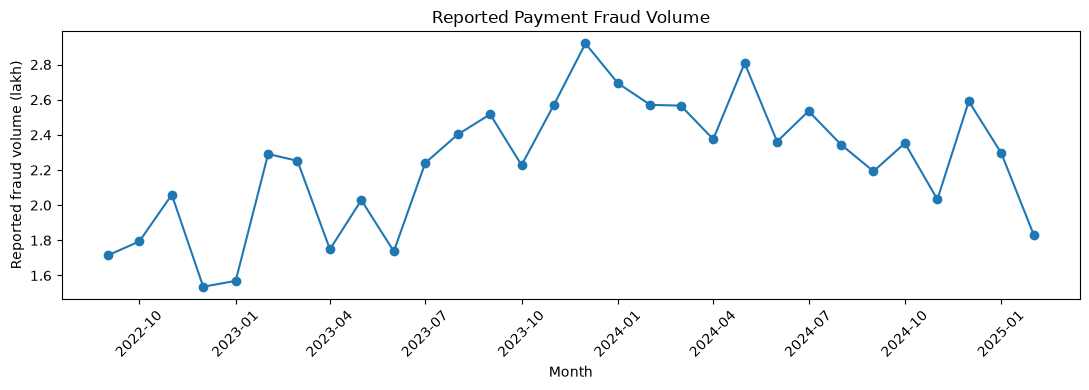

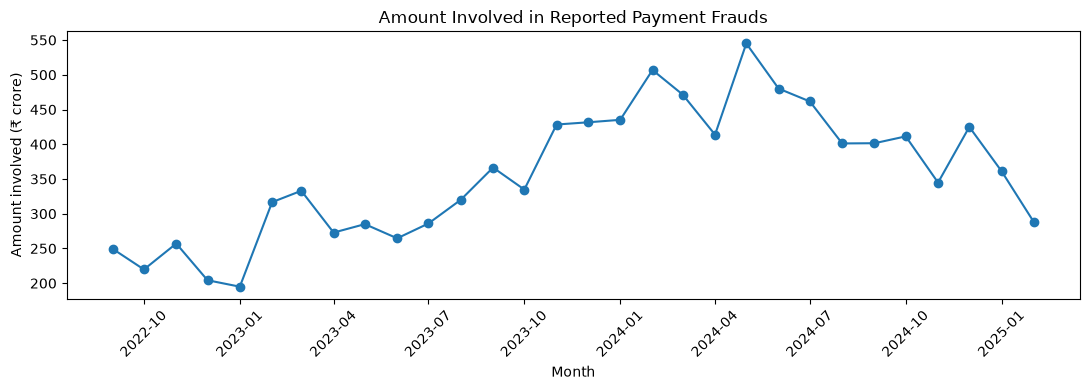

In [12]:

# SECTION 3.8 — TREND CHARTS
# Purpose:
# Visualize reported fraud volume and amount involved over time.
# Why separate charts? The measures use different units and scales.
# Business use: identify broad movements and periods worth investigating.

import matplotlib.pyplot as plt

# Chart 1: number of reported frauds.
plt.figure(figsize=(11, 4))
plt.plot(
    rbi_trend["month"],
    rbi_trend["fraud_volume_lakh"],
    marker="o"
)
plt.title("Reported Payment Fraud Volume")
plt.xlabel("Month")
plt.ylabel("Reported fraud volume (lakh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Chart 2: amount involved in reported frauds.
plt.figure(figsize=(11, 4))
plt.plot(
    rbi_trend["month"],
    rbi_trend["amount_involved_crore"],
    marker="o"
)
plt.title("Amount Involved in Reported Payment Frauds")
plt.xlabel("Month")
plt.ylabel("Amount involved (₹ crore)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

# SECTION 3.9 — PERIOD COMPARISON
# Purpose:
# Compare the average monthly measures in the first 15 and last 15 observations.
# Business use: assess whether the later half differs from the earlier half.
# Limitation: this is not a causal analysis and does not adjust for payment growth.

rbi_periods = rbi_trend.copy()

rbi_periods["period"] = [
    "First 15 months" if i < 15 else "Last 15 months"
    for i in range(len(rbi_periods))
]

period_summary = (
    rbi_periods
    .groupby("period")[
        [
            "fraud_volume_lakh",
            "amount_involved_crore",
            "one_in_x_transactions",
            "fts_bps"
        ]
    ]
    .mean()
    .T
    .reset_index()
    .rename(columns={"index": "Metric"})
)

display(period_summary.round(3))


period,Metric,First 15 months,Last 15 months
0,fraud_volume_lakh,2.046,2.432
1,amount_involved_crore,288.873,425.215
2,one_in_x_transactions,61054.424,75868.684
3,fts_bps,0.147,0.179


In [14]:

# SECTION 3.10 — IMPLIED AMOUNT PER REPORTED FRAUD
# Purpose:
# Divide the reported amount involved by reported fraud volume.
# Volume is reported in lakh, so multiply by 100,000 to obtain the
# number of reported frauds before calculating rupees per fraud.
# Business use: assess whether the aggregate amount changed alongside
# the implied average amount per reported fraud.
# Caveat: this is an aggregate ratio, not the distribution of individual losses.

rbi_trend["implied_amount_per_fraud_rupees"] = (
    rbi_trend["amount_involved_crore"] * 10_000_000
    / (rbi_trend["fraud_volume_lakh"] * 100_000)
)

rbi_trend["period"] = [
    "First 15 months" if i < 15 else "Last 15 months"
    for i in range(len(rbi_trend))
]

implied_amount_summary = (
    rbi_trend.groupby("period")["implied_amount_per_fraud_rupees"]
    .agg(["mean", "median"])
    .rename(columns={
        "mean": "Average monthly implied amount per fraud (₹)",
        "median": "Median monthly implied amount per fraud (₹)"
    })
)

display(implied_amount_summary.round(0))


,Average monthly implied amount per fraud (₹),Median monthly implied amount per fraud (₹)
period,,
First 15 months,14054.0,14048.0
Last 15 months,17473.0,17419.0


### RBI payment-fraud analysis — preliminary findings

**Period analysed:** September 2022 to February 2025 (30 monthly observations).

**Key findings**
1. Average monthly reported fraud volume increased from 2.046 lakh to 2.432 lakh between the first and last 15-month periods (+18.9%).
2. Average monthly amount involved increased from ₹288.9 crore to ₹425.2 crore (+47.2%).
3. The implied average amount involved per reported fraud increased from approximately ₹14,054 to ₹17,473 (+24.3%).
4. May 2024 recorded the highest monthly amount involved in the series, at ₹545.04 crore, followed by lower values in June and July.
5. The FTS indicator increased between the two half-periods, while the one-in-X indicator also increased. These measures capture different dimensions and should not be interpreted interchangeably.

**Limitations:** This is descriptive analysis of reported aggregate frauds. It does not establish causality, account for digital-payment growth, identify specific fraud types or determine the commercial effectiveness of any prevention solution.

**Implication:** The findings justify further investigation into the addressable fraud-prevention opportunity, but do not independently establish market size, customer demand or investment attractiveness.

In [16]:

# SECTION 4.1 — LOAD AND INSPECT TRANSACTION DATA
# Purpose: Load both CSV files directly from the Project 1 folder.
# Why: Avoid repeated file-picker steps and keep the workflow reproducible.
# Next: Inspect columns, missing values and duplicates before joining.

from pathlib import Path
import pandas as pd

# Define the project folder where both CSV files are stored.
project_folder = Path(r"E:\Projects_website\Liminal Portfolio\Project 1")

# Load the two files directly.
transactions = pd.read_csv(project_folder / "transactions.csv")
fraud_labels = pd.read_csv(project_folder / "fraud_labels.csv")

# Inspect the structure of the transaction dataset.
print("TRANSACTIONS")
print("Shape:", transactions.shape)
print("Columns:", transactions.columns.tolist())
print("Duplicate rows:", transactions.duplicated().sum())
print("\nMissing values by column:")
display(transactions.isna().sum().to_frame("missing_count"))

# Inspect the separate fraud-label file.
print("\nFRAUD LABELS")
print("Shape:", fraud_labels.shape)
print("Columns:", fraud_labels.columns.tolist())
print("Duplicate rows:", fraud_labels.duplicated().sum())
display(fraud_labels.head())


TRANSACTIONS
Shape: (20000, 30)
Columns: ['transaction_id', 'user_id', 'receiver_id', 'receiver_type', 'amount', 'timestamp', 'date', 'hour_of_day', 'day_of_week', 'is_weekend', 'is_night_transaction', 'time_since_last_txn_min', 'transaction_type', 'payment_app', 'device_type', 'status', 'user_city_tier', 'user_kyc_status', 'user_avg_monthly_txn', 'user_avg_txn_value', 'user_loyalty_score', 'new_device_flag', 'ip_location_mismatch', 'failed_attempts_last_24h', 'transaction_velocity', 'amount_deviation_score', 'is_fraud', 'recurring_payment_flag', 'balance_after_transaction', 'transaction_frequency_score']
Duplicate rows: 0

Missing values by column:


,missing_count
transaction_id,0
user_id,0
receiver_id,0
receiver_type,0
amount,0
timestamp,0
date,0
hour_of_day,0
day_of_week,0
is_weekend,0



FRAUD LABELS
Shape: (20000, 11)
Columns: ['transaction_id', 'user_id', 'receiver_id', 'amount', 'timestamp', 'is_fraud', 'new_device_flag', 'ip_location_mismatch', 'failed_attempts_last_24h', 'transaction_velocity', 'amount_deviation_score']
Duplicate rows: 0


,transaction_id,user_id,receiver_id,amount,timestamp,is_fraud,new_device_flag,ip_location_mismatch,failed_attempts_last_24h,transaction_velocity,amount_deviation_score
0,TXN0000001,USR01603,MRC0374,1650.84,2024-12-26 14:52:00,0,0,0,0,0.0,0.5146
1,TXN0000002,USR01759,MRC0274,599.20,2024-06-29 00:09:24,0,0,0,1,0.0,0.7026
2,TXN0000003,USR01894,MRC0122,261.36,2024-02-21 05:08:33,0,0,0,0,0.0,0.1547
3,TXN0000004,USR00606,USR00692,215.71,2024-08-09 18:52:33,0,0,0,0,0.0,0.0078
4,TXN0000005,USR01246,MRC0007,411.15,2024-02-18 06:37:11,0,0,0,1,1.0,0.1170


In [17]:

# SECTION 4.2 — VALIDATE FRAUD LABELS AND RECORD MATCHING
# Purpose:
# Confirm that both files refer to the same transactions and that
# their overlapping fields agree before we analyse fraud patterns.
# Business use: establish data integrity and quantify label imbalance.
# Limitation: agreement verifies consistency, not the real-world validity
# of synthetic fraud labels.

# 1. Check whether transaction IDs are unique in each file.
print("Unique transaction IDs")
print("Transactions:", transactions["transaction_id"].nunique())
print("Fraud labels:", fraud_labels["transaction_id"].nunique())

# 2. Check whether both files contain exactly the same transaction IDs.
transaction_ids = set(transactions["transaction_id"])
label_ids = set(fraud_labels["transaction_id"])

print("\nTransaction ID reconciliation")
print("IDs present only in transactions:", len(transaction_ids - label_ids))
print("IDs present only in labels:", len(label_ids - transaction_ids))

# 3. Compare the fraud labels for matching transactions.
label_check = transactions[
    ["transaction_id", "is_fraud"]
].merge(
    fraud_labels[["transaction_id", "is_fraud"]],
    on="transaction_id",
    how="outer",
    suffixes=("_main", "_labels"),
    indicator=True,
    validate="one_to_one"
)

print("\nJoin status:")
print(label_check["_merge"].value_counts())

matched = label_check[label_check["_merge"] == "both"].copy()
label_mismatches = (
    matched["is_fraud_main"] != matched["is_fraud_labels"]
).sum()

print("Fraud-label mismatches:", label_mismatches)

# 4. Compare other fields shared by both files.
shared_fields = [
    column for column in fraud_labels.columns
    if column in transactions.columns
    and column not in ["transaction_id", "is_fraud"]
]

field_mismatches = {}

for column in shared_fields:
    comparison = transactions[
        ["transaction_id", column]
    ].merge(
        fraud_labels[["transaction_id", column]],
        on="transaction_id",
        how="inner",
        suffixes=("_main", "_labels"),
        validate="one_to_one"
    )

    # Treat two missing values as agreeing.
    equal_values = (
        comparison[f"{column}_main"].eq(comparison[f"{column}_labels"])
        | (
            comparison[f"{column}_main"].isna()
            & comparison[f"{column}_labels"].isna()
        )
    )

    field_mismatches[column] = int((~equal_values).sum())

print("\nMismatches in overlapping fields:")
display(
    pd.DataFrame(
        list(field_mismatches.items()),
        columns=["field", "mismatch_count"]
    )
)

# 5. Examine the fraud-label distribution in the main dataset.
label_counts = transactions["is_fraud"].value_counts(dropna=False)
label_percentages = (
    transactions["is_fraud"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
)

label_summary = pd.DataFrame({
    "transaction_count": label_counts,
    "percentage": label_percentages
})

print("\nFraud-label distribution")
display(label_summary.round(2))


Unique transaction IDs
Transactions: 20000
Fraud labels: 20000

Transaction ID reconciliation
IDs present only in transactions: 0
IDs present only in labels: 0

Join status:
_merge
both          20000
left_only         0
right_only        0
Name: count, dtype: int64
Fraud-label mismatches: 0

Mismatches in overlapping fields:


,field,mismatch_count
0,user_id,0
1,receiver_id,0
2,amount,0
3,timestamp,0
4,new_device_flag,0
5,ip_location_mismatch,0
6,failed_attempts_last_24h,0
7,transaction_velocity,0
8,amount_deviation_score,0



Fraud-label distribution


,transaction_count,percentage
is_fraud,,
0,19237,96.18
1,763,3.82


In [18]:

# SECTION 4.3 — FRAUD-LABEL RATE BY RISK SIGNAL
# Purpose:
# Compare the proportion of fraud-labelled transactions across risk signals.
# Why: raw fraud counts alone are misleading when group sizes differ.
# Business use: identify patterns worth investigating in a risk-control review.
# Limitation: these are synthetic labels generated using risk-related rules;
# associations may reflect the dataset's construction, not real-world behaviour.

risk_flags = {
    "new_device_flag": "New device",
    "ip_location_mismatch": "IP-location mismatch",
    "is_night_transaction": "Night transaction",
}

risk_results = []

for column, label in risk_flags.items():
    grouped = (
        transactions.groupby(column, dropna=False)["is_fraud"]
        .agg(transaction_count="size", fraud_count="sum", fraud_rate="mean")
        .reset_index()
    )

    for _, row in grouped.iterrows():
        risk_results.append({
            "Risk signal": label,
            "Signal value": row[column],
            "Transactions": int(row["transaction_count"]),
            "Fraud-labelled transactions": int(row["fraud_count"]),
            "Fraud-label rate (%)": row["fraud_rate"] * 100
        })

# Failed attempts are a count, so compare transactions with zero vs one or more.
transactions["has_failed_attempts"] = (
    transactions["failed_attempts_last_24h"] > 0
).map({False: "No failed attempts", True: "One or more failed attempts"})

failed_group = (
    transactions.groupby("has_failed_attempts")["is_fraud"]
    .agg(transaction_count="size", fraud_count="sum", fraud_rate="mean")
    .reset_index()
)

for _, row in failed_group.iterrows():
    risk_results.append({
        "Risk signal": "Recent failed attempts",
        "Signal value": row["has_failed_attempts"],
        "Transactions": int(row["transaction_count"]),
        "Fraud-labelled transactions": int(row["fraud_count"]),
        "Fraud-label rate (%)": row["fraud_rate"] * 100
    })

risk_summary = pd.DataFrame(risk_results)

display(
    risk_summary.sort_values(
        ["Risk signal", "Fraud-label rate (%)"],
        ascending=[True, False]
    ).round(2)
)


,Risk signal,Signal value,Transactions,Fraud-labelled transactions,Fraud-label rate (%)
3,IP-location mismatch,1.0,769,75,9.75
2,IP-location mismatch,0.0,19231,688,3.58
1,New device,1.0,1296,160,12.35
0,New device,0.0,18704,603,3.22
5,Night transaction,1.0,6492,342,5.27
4,Night transaction,0.0,13508,421,3.12
7,Recent failed attempts,One or more failed attempts,5686,268,4.71
6,Recent failed attempts,No failed attempts,14314,495,3.46


In [19]:

# SECTION 4.4 — AMOUNT SEGMENTS
# Purpose:
# Compare fraud-label rates across transaction-amount bands.
# Why: a higher amount may change the financial exposure even if the
# fraud-label rate is not higher.
# Business use: begin separating frequency risk from potential value at risk.
# Limitation: synthetic data; amount bands do not establish causal risk.

# Create interpretable amount bands using the observed transaction amounts.
transactions["amount_band"] = pd.cut(
    transactions["amount"],
    bins=[-float("inf"), 500, 2000, 5000, 10000, float("inf")],
    labels=["Up to ₹500", "₹501–2,000", "₹2,001–5,000",
            "₹5,001–10,000", "Above ₹10,000"]
)

amount_summary = (
    transactions.groupby("amount_band", observed=False)["is_fraud"]
    .agg(
        transaction_count="size",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

amount_summary["fraud_rate_pct"] = amount_summary["fraud_rate"] * 100

display(
    amount_summary[
        ["amount_band", "transaction_count", "fraud_count", "fraud_rate_pct"]
    ].round(2)
)


,amount_band,transaction_count,fraud_count,fraud_rate_pct
0,Up to ₹500,9354,355,3.80
1,"₹501–2,000",8753,322,3.68
2,"₹2,001–5,000",1668,72,4.32
3,"₹5,001–10,000",202,13,6.44
4,"Above ₹10,000",23,1,4.35


In [20]:

# SECTION 4.5 — TRANSACTION TYPE AND PAYMENT APP
# Purpose:
# Compare fraud-label rates across transaction types and payment apps.
# Business use: identify categories that may warrant deeper investigation.
# Important: display group sizes alongside rates to avoid overinterpreting
# small samples. These results remain descriptive of synthetic data.

category_results = []

for column in ["transaction_type", "payment_app", "receiver_type", "status"]:
    grouped = (
        transactions.groupby(column, dropna=False)["is_fraud"]
        .agg(
            transaction_count="size",
            fraud_count="sum",
            fraud_rate="mean"
        )
        .reset_index()
        .rename(columns={column: "category"})
    )

    grouped["category_field"] = column
    grouped["fraud_rate_pct"] = grouped["fraud_rate"] * 100

    category_results.append(
        grouped[
            [
                "category_field",
                "category",
                "transaction_count",
                "fraud_count",
                "fraud_rate_pct"
            ]
        ]
    )

category_summary = pd.concat(category_results, ignore_index=True)

# Show the categories with the highest observed rates within each field.
# Keep counts visible so that small groups are easy to spot.
for field in ["transaction_type", "payment_app", "receiver_type", "status"]:
    print(f"\nFraud-label rate by {field}")
    display(
        category_summary[
            category_summary["category_field"] == field
        ].sort_values(
            "fraud_rate_pct", ascending=False
        ).round(2)
    )



Fraud-label rate by transaction_type


,category_field,category,transaction_count,fraud_count,fraud_rate_pct
2,transaction_type,P2M,7014,280,3.99
5,transaction_type,Subscription,1381,55,3.98
4,transaction_type,Recharge,2063,77,3.73
3,transaction_type,P2P,4881,182,3.73
0,transaction_type,Bill Payment,3033,112,3.69
1,transaction_type,EMI,1628,57,3.50



Fraud-label rate by payment_app


,category_field,category,transaction_count,fraud_count,fraud_rate_pct
11,payment_app,WhatsApp Pay,781,34,4.35
6,payment_app,Amazon Pay,1584,66,4.17
9,payment_app,Paytm,3738,149,3.99
8,payment_app,GPay,6438,245,3.81
10,payment_app,PhonePe,5864,220,3.75
7,payment_app,BHIM,1595,49,3.07



Fraud-label rate by receiver_type


,category_field,category,transaction_count,fraud_count,fraud_rate_pct
12,receiver_type,Merchant,15119,581,3.84
13,receiver_type,User,4881,182,3.73



Fraud-label rate by status


,category_field,category,transaction_count,fraud_count,fraud_rate_pct
15,status,Pending,557,28,5.03
16,status,Success,17628,669,3.80
14,status,Failed,1815,66,3.64


In [21]:

# SECTION 4.6 — FINANCIAL EXPOSURE BY FRAUD LABEL
# Purpose:
# Compare transaction counts and transaction amounts by synthetic fraud label.
# Business use: distinguish frequency from monetary exposure.
# Critical limitation: transaction value is not confirmed loss or recoverable loss.
# Do not interpret these figures as actual Indian payment-system losses.

value_summary = (
    transactions.groupby("is_fraud")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_transaction_value=("amount", "sum"),
        average_transaction_value=("amount", "mean"),
        median_transaction_value=("amount", "median"),
        maximum_transaction_value=("amount", "max")
    )
    .reset_index()
)

# Calculate each label group's share of total transaction value.
total_value = transactions["amount"].sum()

value_summary["transaction_value_share_pct"] = (
    value_summary["total_transaction_value"] / total_value * 100
)

# Add a readable label for the output.
value_summary["label"] = value_summary["is_fraud"].map({
    0: "Non-fraud-labelled",
    1: "Fraud-labelled"
})

display(
    value_summary[
        [
            "label",
            "transaction_count",
            "total_transaction_value",
            "transaction_value_share_pct",
            "average_transaction_value",
            "median_transaction_value",
            "maximum_transaction_value"
        ]
    ].round(2)
)


,label,transaction_count,total_transaction_value,transaction_value_share_pct,average_transaction_value,median_transaction_value,maximum_transaction_value
0,Non-fraud-labelled,19237,16821148.52,95.92,874.42,539.83,32259.72
1,Fraud-labelled,763,715788.55,4.08,938.12,545.39,10699.42


In [22]:

# SECTION 4.7 — COMPARE FRAUD-LABELLED AND NON-FRAUD-LABELLED GROUPS
# Purpose:
# Express the difference in average transaction value as a simple ratio.
# Business use: communicate the result in one concise metric.
# Limitation: this is a descriptive comparison, not a causal effect.

group_means = transactions.groupby("is_fraud")["amount"].mean()

non_fraud_mean = group_means.loc[0]
fraud_mean = group_means.loc[1]

print(f"Average amount, non-fraud-labelled: ₹{non_fraud_mean:,.2f}")
print(f"Average amount, fraud-labelled:     ₹{fraud_mean:,.2f}")
print(f"Ratio of average amounts:           {fraud_mean / non_fraud_mean:.2f}x")

print(
    "\nInterpretation: this compares transaction amounts in the synthetic "
    "dataset. It does not estimate actual fraud losses or the savings "
    "a prevention product could deliver."
)


Average amount, non-fraud-labelled: ₹874.42
Average amount, fraud-labelled:     ₹938.12
Ratio of average amounts:           1.07x

Interpretation: this compares transaction amounts in the synthetic dataset. It does not estimate actual fraud losses or the savings a prevention product could deliver.


In [23]:

# SECTION 4.8 — CONSOLIDATED DESCRIPTIVE FINDINGS
# Purpose:
# Create a compact evidence table for the notebook and executive deck.
# Why: decision-makers need the finding, its interpretation and its limitation.
# These observations describe synthetic labels and are not real-world estimates.

findings = pd.DataFrame([
    {
        "Finding": "New device",
        "Observed evidence": "12.35% label rate vs 3.22% without",
        "Business interpretation": "Strongest observed association among the four tested signals",
        "Limitation": "Label-generation rules may directly use this signal"
    },
    {
        "Finding": "IP-location mismatch",
        "Observed evidence": "9.75% vs 3.58% without mismatch",
        "Business interpretation": "Higher label rate in the flagged group",
        "Limitation": "Association may reflect synthetic label construction"
    },
    {
        "Finding": "Night transaction",
        "Observed evidence": "5.27% vs 3.12% during non-night transactions",
        "Business interpretation": "More modest difference in label rate",
        "Limitation": "Not independently validated on real transactions"
    },
    {
        "Finding": "Transaction amount",
        "Observed evidence": "Average ₹938.12 vs ₹874.42",
        "Business interpretation": "Average amounts are relatively similar",
        "Limitation": "Transaction amount is not confirmed fraud loss"
    },
    {
        "Finding": "Payment app",
        "Observed evidence": "Rates range from 3.07% to 4.35%",
        "Business interpretation": "Some variation, but no basis for ranking actual providers",
        "Limitation": "Synthetic population and potential differences in user mix"
    },
    {
        "Finding": "Data integrity",
        "Observed evidence": "20,000 IDs matched; zero label mismatches",
        "Business interpretation": "The two supplied files are internally consistent",
        "Limitation": "Consistency does not validate real-world representativeness"
    }
])

display(findings)


,Finding,Observed evidence,Business interpretation,Limitation
0,New device,12.35% label rate vs 3.22% without,Strongest observed association among the four ...,Label-generation rules may directly use this s...
1,IP-location mismatch,9.75% vs 3.58% without mismatch,Higher label rate in the flagged group,Association may reflect synthetic label constr...
2,Night transaction,5.27% vs 3.12% during non-night transactions,More modest difference in label rate,Not independently validated on real transactions
3,Transaction amount,Average ₹938.12 vs ₹874.42,Average amounts are relatively similar,Transaction amount is not confirmed fraud loss
4,Payment app,Rates range from 3.07% to 4.35%,"Some variation, but no basis for ranking actua...",Synthetic population and potential differences...
5,Data integrity,"20,000 IDs matched; zero label mismatches",The two supplied files are internally consistent,Consistency does not validate real-world repre...


### 5.1 Preliminary market evidence and existing controls

**Source 1 — NPCI UPI Product Statistics**

- **Evidence collected:** Monthly UPI transaction volume, transaction value and number of banks live on UPI.
- **Purpose:** Establish UPI ecosystem scale and analyse historical growth.
- **Commercial implication:** Growth in payment activity establishes a large and evolving ecosystem in which fraud prevention operates.
- **Limitation:** Payment growth does not establish fraud growth, an unmet buyer need or demand for a new vendor.
- **Next action:** Extract monthly observations for comparable completed financial years and calculate year-on-year growth.

**Source 2 — RBI Circular CO.DPSS.RPPD.No.S987/04.03.001/2024-25, dated 30 December 2024**

- **Evidence collected:** Beneficiary bank account name lookup for RTGS and NEFT, to be offered by participating banks no later than 1 April 2025.
- **Purpose:** Understand an existing preventive control, its operating scope and its requirements.
- **Commercial implication:** Beneficiary verification is an established control objective. Any proposed additional solution must demonstrate value beyond existing measures.
- **Limitation:** The circular concerns RTGS and NEFT. It does not establish a deficiency in UPI controls or demonstrate the effectiveness of the facility.
- **Next action:** Investigate documented buyer pain points and control gaps separately.

**Source 3 — Ministry of Finance press release, 11 March 2025, Release ID 2110405**

- **Evidence collected:** Digital-payment volume and value from FY2020–21 to FY2024–25, with FY2024–25 data reported through January 2025. The release also documents existing prevention, monitoring, authentication and awareness initiatives.
- **Purpose:** Establish the broader digital-payment context and map the existing control environment.
- **Commercial implication:** The ecosystem is substantial and already has multiple prevention mechanisms. The opportunity assessment must identify a specific, evidenced gap rather than assume that additional technology is needed.
- **Limitation:** The release's payment statistics cover digital payments broadly, not exclusively UPI. The FY2024–25 figures are partial-year data.
- **Next action:** Identify the target buyer, document the unresolved problem and establish whether a proposed intervention can deliver measurable incremental value.

In [24]:

# SECTION 5.1 — MARKET RESEARCH REGISTER
# Purpose: Create a structured log of evidence for the commercial assessment.
# Why: Every important conclusion must be traceable to a source or assumption.
# Next: Populate the register as we review official and industry sources.

import pandas as pd

research_register = pd.DataFrame([
    {
        "Research question": "How large and fast-growing is the payment ecosystem?",
        "Evidence needed": "Transaction volume, value and growth",
        "Preferred source": "NPCI / RBI",
        "Finding": "",
        "Business implication": "",
        "Limitation": "",
        "Source URL": ""
    },
    {
        "Research question": "What fraud-prevention controls already exist?",
        "Evidence needed": "Regulatory requirements and current capabilities",
        "Preferred source": "RBI / NPCI",
        "Finding": "",
        "Business implication": "",
        "Limitation": "",
        "Source URL": ""
    },
    {
        "Research question": "Where is an unmet buyer need documented?",
        "Evidence needed": "Buyer interviews, credible industry studies, documented gaps",
        "Preferred source": "Industry research / bank disclosures",
        "Finding": "",
        "Business implication": "",
        "Limitation": "",
        "Source URL": ""
    },
    {
        "Research question": "Can a solution create measurable economic value?",
        "Evidence needed": "Preventable loss, effectiveness, operating cost and pricing",
        "Preferred source": "Sourced facts plus explicit model assumptions",
        "Finding": "",
        "Business implication": "",
        "Limitation": "",
        "Source URL": ""
    }
])

display(research_register)


,Research question,Evidence needed,Preferred source,Finding,Business implication,Limitation,Source URL
0,How large and fast-growing is the payment ecos...,"Transaction volume, value and growth",NPCI / RBI,,,,
1,What fraud-prevention controls already exist?,Regulatory requirements and current capabilities,RBI / NPCI,,,,
2,Where is an unmet buyer need documented?,"Buyer interviews, credible industry studies, d...",Industry research / bank disclosures,,,,
3,Can a solution create measurable economic value?,"Preventable loss, effectiveness, operating cos...",Sourced facts plus explicit model assumptions,,,,


In [27]:

# SECTION 5.2 — LOAD AND INSPECT NPCI UPI STATISTICS
# Purpose:
# Load the UPI statistics workbook directly from the project folder.
# Inspect its structure before cleaning dates or calculating growth.

from pathlib import Path
import pandas as pd

# Define the saved workbook path.
upi_file = Path(
    r"E:\Projects_website\Liminal Portfolio\Project 1\UPI_monthly_stats.xlsx"
)

# Confirm that Python can find the workbook before attempting to read it.
if not upi_file.exists():
    raise FileNotFoundError(f"Workbook not found: {upi_file}")

# Inspect worksheet names so we know which sheet contains the data.
upi_workbook = pd.ExcelFile(upi_file)
print("Workbook:", upi_file.name)
print("Worksheets:", upi_workbook.sheet_names)

# Load the first worksheet. We'll verify its columns in the output.
upi_raw = pd.read_excel(
    upi_file,
    sheet_name=upi_workbook.sheet_names[0]
)

# Check dimensions, column names, sample records and missing values.
print("\nDataset shape:", upi_raw.shape)
print("\nColumn names:")
print(upi_raw.columns.tolist())

print("\nFirst five rows:")
display(upi_raw.head())

print("\nMissing values by column:")
display(upi_raw.isna().sum().to_frame("missing_count"))


Workbook: UPI_monthly_stats.xlsx
Worksheets: ['Product Statistics']

Dataset shape: (48, 6)

Column names:
['Month', 'Volume (In Mn.)', 'Avg. Daily Volume (In Mn.)', 'Value (In Cr.)', 'Avg. Daily Value (In Cr.)', 'Banks live on UPI']

First five rows:


,Month,Volume (In Mn.),Avg. Daily Volume (In Mn.),Value (In Cr.),Avg. Daily Value (In Cr.),Banks live on UPI
0,2022-04-01,5583.05,186.1000,970038.48,32334.6200,316
1,2022-05-01,5955.20,192.1000,1040220.53,33555.5000,323
2,2022-06-01,5862.75,195.4250,1014412.63,33813.7543,330
3,2022-07-01,6288.40,202.8516,1063117.04,34294.0981,338
4,2022-08-01,6579.63,212.2461,1073162.17,34618.1345,346



Missing values by column:


,missing_count
Month,0
Volume (In Mn.),0
Avg. Daily Volume (In Mn.),0
Value (In Cr.),0
Avg. Daily Value (In Cr.),0
Banks live on UPI,0


In [28]:

# SECTION 5.3 — VALIDATE NPCI MONTHLY DATA
# Purpose:
# Confirm the date range, uniqueness of months, monthly continuity,
# numeric data types and basic data quality before analysis.
#
# Why:
# Growth calculations require correctly ordered, consecutive months.
# This cell checks whether the expected April 2022–March 2026 period
# contains all 48 unique monthly observations.

# Work on a copy so the originally imported data remains unchanged.
upi = upi_raw.copy()

# Convert Month into a proper datetime column.
# The source output already displays dates like 2022-04-01.
upi["Month"] = pd.to_datetime(upi["Month"], errors="raise")

# Sort chronologically so later month-on-month calculations are correct.
upi = upi.sort_values("Month").reset_index(drop=True)

# Identify duplicate months and missing months in the expected period.
expected_months = pd.date_range(
    start="2022-04-01",
    end="2026-03-01",
    freq="MS"
)

actual_months = pd.DatetimeIndex(upi["Month"].dropna().unique())
missing_months = expected_months.difference(actual_months)

print("Number of rows:", len(upi))
print("Unique months:", upi["Month"].nunique())
print("Duplicate month rows:", upi["Month"].duplicated().sum())
print("First month:", upi["Month"].min().strftime("%b-%Y"))
print("Last month:", upi["Month"].max().strftime("%b-%Y"))
print("Missing months:", [m.strftime("%b-%Y") for m in missing_months])

# Confirm that all measurement columns are numeric.
numeric_columns = [
    "Volume (In Mn.)",
    "Avg. Daily Volume (In Mn.)",
    "Value (In Cr.)",
    "Avg. Daily Value (In Cr.)",
    "Banks live on UPI"
]

for column in numeric_columns:
    upi[column] = pd.to_numeric(upi[column], errors="raise")

print("\nData types:")
print(upi.dtypes)

print("\nData quality checks:")
print("Missing values by column:")
display(upi.isna().sum().to_frame("missing_count"))

print("\nChronological sample:")
display(upi.head(3))

print("\nLatest three months:")
display(upi.tail(3))


Number of rows: 48
Unique months: 48
Duplicate month rows: 0
First month: Apr-2022
Last month: Mar-2026
Missing months: []

Data types:
Month                         datetime64[us]
Volume (In Mn.)                      float64
Avg. Daily Volume (In Mn.)           float64
Value (In Cr.)                       float64
Avg. Daily Value (In Cr.)            float64
Banks live on UPI                      int64
dtype: object

Data quality checks:
Missing values by column:


,missing_count
Month,0
Volume (In Mn.),0
Avg. Daily Volume (In Mn.),0
Value (In Cr.),0
Avg. Daily Value (In Cr.),0
Banks live on UPI,0



Chronological sample:


,Month,Volume (In Mn.),Avg. Daily Volume (In Mn.),Value (In Cr.),Avg. Daily Value (In Cr.),Banks live on UPI
0,2022-04-01,5583.05,186.100,970038.48,32334.6200,316
1,2022-05-01,5955.20,192.100,1040220.53,33555.5000,323
2,2022-06-01,5862.75,195.425,1014412.63,33813.7543,330



Latest three months:


,Month,Volume (In Mn.),Avg. Daily Volume (In Mn.),Value (In Cr.),Avg. Daily Value (In Cr.),Banks live on UPI
45,2026-01-01,21703.46,700.1116,2833481.26,91402.6213,691
46,2026-02-01,20394.20,728.3643,2684229.30,95865.3321,694
47,2026-03-01,22641.14,730.3594,2952542.03,95243.2913,705


In [29]:

# SECTION 5.4 — UPI GROWTH AND ECOSYSTEM EXPANSION
# Purpose:
# Measure monthly and annual changes in UPI volume, value and
# participating banks.
#
# Why:
# Transaction volume measures activity; transaction value measures
# the monetary scale; banks live indicates ecosystem participation.
#
# How to interpret:
# MoM compares with the previous month.
# YoY compares with the same month one year earlier, reducing
# some seasonality concerns. Neither measure establishes fraud risk.

# Work on a copy so the validated source table remains unchanged.
upi_analysis = upi.copy()

# Calculate month-on-month percentage growth.
# The first month has no previous month, so its growth is undefined.
for column, suffix in [
    ("Volume (In Mn.)", "volume"),
    ("Value (In Cr.)", "value"),
    ("Banks live on UPI", "banks")
]:
    upi_analysis[f"{suffix}_mom_pct"] = (
        upi_analysis[column].pct_change() * 100
    )

# Calculate year-on-year percentage growth.
# The first 12 months have no comparable month from the prior year.
for column, suffix in [
    ("Volume (In Mn.)", "volume"),
    ("Value (In Cr.)", "value"),
    ("Banks live on UPI", "banks")
]:
    upi_analysis[f"{suffix}_yoy_pct"] = (
        upi_analysis[column].pct_change(periods=12) * 100
    )

# Calculate implied average transaction value.
# Volume is in millions of transactions; value is in crore rupees.
# ₹ crore / million transactions = ₹ hundreds per transaction.
upi_analysis["avg_transaction_value_rupees"] = (
    upi_analysis["Value (In Cr.)"]
    / upi_analysis["Volume (In Mn.)"]
    * 100
)

# Show a compact view of the latest observations.
columns_to_display = [
    "Month",
    "Volume (In Mn.)",
    "Value (In Cr.)",
    "Banks live on UPI",
    "volume_mom_pct",
    "value_mom_pct",
    "volume_yoy_pct",
    "value_yoy_pct",
    "banks_yoy_pct",
    "avg_transaction_value_rupees"
]

display(
    upi_analysis[columns_to_display]
    .tail(15)
    .round(2)
)


C:\Users\admin\AppData\Local\Temp\ipykernel_132\258954506.py:66: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,Month,Volume (In Mn.),Value (In Cr.),Banks live on UPI,volume_mom_pct,value_mom_pct,volume_yoy_pct,value_yoy_pct,banks_yoy_pct,avg_transaction_value_rupees
33,2025-01-01,16996.01,2348037.11,647,1.59,1.00,39.28,27.54,17.64,13815.23
34,2025-02-01,16106.19,2196481.70,653,-5.24,-6.45,33.08,20.17,16.61,13637.50
35,2025-03-01,18301.51,2477221.59,661,13.63,12.78,36.17,25.22,15.56,13535.61
36,2025-04-01,17893.42,2394925.87,668,-2.23,-3.32,34.50,21.91,14.58,13384.39
37,2025-05-01,18677.45,2514297.01,673,4.38,4.98,33.07,22.95,12.54,13461.67
38,2025-06-01,18395.01,2403930.69,675,-1.51,-4.39,32.48,19.77,12.13,13068.38
39,2025-07-01,19467.95,2508498.10,684,5.83,4.35,34.86,21.52,13.06,12885.27
40,2025-08-01,20008.31,2485472.90,688,2.78,-0.92,33.72,20.61,13.16,12422.20
41,2025-09-01,19633.43,2489736.52,686,-1.87,0.17,30.53,20.63,10.29,12681.11
42,2025-10-01,20700.92,2727790.71,683,5.44,9.56,24.82,16.09,8.07,13177.15


In [30]:

# SECTION 5.4A — CORRECT AVERAGE TRANSACTION VALUE
# Purpose: Correct the unit conversion for rupees per transaction.
# Value is in ₹ crore; volume is in millions of transactions.
# Therefore, (₹ crore / million transactions) × 10 = rupees/transaction.

upi_analysis["avg_transaction_value_rupees"] = (
    upi_analysis["Value (In Cr.)"]
    / upi_analysis["Volume (In Mn.)"]
    * 10
)

# Display the corrected average transaction value for the latest 15 months.
display(
    upi_analysis[
        ["Month", "avg_transaction_value_rupees"]
    ].tail(15).round(2)
)


C:\Users\admin\AppData\Local\Temp\ipykernel_132\159502169.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(15).round(2)


,Month,avg_transaction_value_rupees
33,2025-01-01,1381.52
34,2025-02-01,1363.75
35,2025-03-01,1353.56
36,2025-04-01,1338.44
37,2025-05-01,1346.17
38,2025-06-01,1306.84
39,2025-07-01,1288.53
40,2025-08-01,1242.22
41,2025-09-01,1268.11
42,2025-10-01,1317.71


In [31]:

# SECTION 5.4B — ALIGN UPI ACTIVITY WITH RBI FRAUD INDICATORS
#
# PURPOSE:
# Compare UPI ecosystem growth with broader reported domestic payment-fraud
# indicators over the months available in BOTH datasets.
#
# WHY:
# A consulting analysis should first establish whether the periods align
# and then compare trends without pretending the datasets cover identical
# transaction populations.
#
# HOW:
# 1. Select only the required columns from each cleaned dataset.
# 2. Merge on month using an inner join, retaining common months only.
# 3. Validate the overlap and calculate indexed trends (starting at 100).
#
# HOW TO USE THE OUTPUT:
# Indexed values make it easier to compare relative movement over time.
# They do NOT establish causation or calculate a UPI fraud rate.

upi_compare = upi[
    ["Month", "Volume (In Mn.)", "Value (In Cr.)"]
].copy()

rbi_compare = rbi_fraud[
    [
        "month",
        "fraud_volume_lakh",
        "amount_involved_crore",
        "fts_bps"
    ]
].copy()

# Use a consistent column name for the month before merging.
upi_compare = upi_compare.rename(columns={"Month": "month"})

# Inner join ensures that only months present in both datasets are retained.
comparison = pd.merge(
    upi_compare,
    rbi_compare,
    on="month",
    how="inner",
    validate="one_to_one"
).sort_values("month").reset_index(drop=True)

# Check that the comparison covers the expected overlap.
print("Common monthly observations:", len(comparison))
print("First common month:", comparison["month"].min().strftime("%B %Y"))
print("Last common month:", comparison["month"].max().strftime("%B %Y"))
print("Duplicate months:", comparison["month"].duplicated().sum())
print("Missing values by column:")
display(comparison.isna().sum().to_frame("missing_values"))

# Index each series to 100 in the first common month.
# This compares proportional movement, not absolute quantities.
index_columns = {
    "Volume (In Mn.)": "upi_volume_index",
    "Value (In Cr.)": "upi_value_index",
    "fraud_volume_lakh": "rbi_fraud_volume_index",
    "amount_involved_crore": "rbi_fraud_amount_index",
    "fts_bps": "rbi_fts_index"
}

for source_column, index_column in index_columns.items():
    base_value = comparison[source_column].iloc[0]
    comparison[index_column] = (
        comparison[source_column] / base_value * 100
    )

# Display selected observations to inspect the start, middle, and end.
display(
    comparison.loc[
        comparison.index.isin(
            [0, len(comparison) // 2, len(comparison) - 1]
        ),
        [
            "month",
            "upi_volume_index",
            "upi_value_index",
            "rbi_fraud_volume_index",
            "rbi_fraud_amount_index",
            "rbi_fts_index"
        ]
    ].round(2)
)


Common monthly observations: 30
First common month: September 2022
Last common month: February 2025
Duplicate months: 0
Missing values by column:


,missing_values
month,0
Volume (In Mn.),0
Value (In Cr.),0
fraud_volume_lakh,0
amount_involved_crore,0
fts_bps,0


C:\Users\admin\AppData\Local\Temp\ipykernel_132\2395230991.py:84: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,month,upi_volume_index,upi_value_index,rbi_fraud_volume_index,rbi_fraud_amount_index,rbi_fts_index
0,2022-09-01,100.00,100.00,100.00,100.00,100.00
15,2023-12-01,177.27,163.28,170.26,173.03,147.24
29,2025-02-01,237.53,196.74,106.81,115.38,95.28


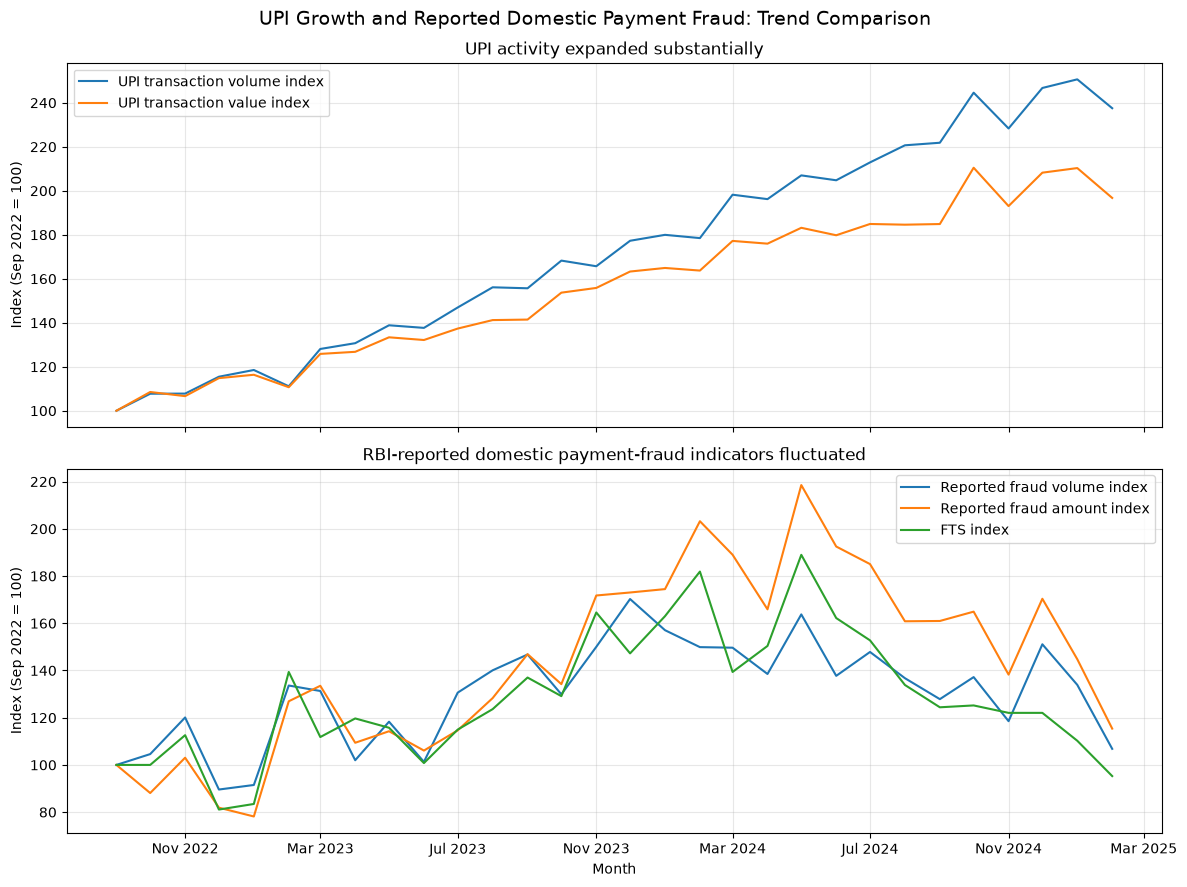

In [32]:

# SECTION 5.4C — VISUALISE THE COMPARATIVE TRENDS
#
# PURPOSE:
# Turn the indexed table into a chart that can support our research narrative.
#
# WHY TWO PANELS:
# UPI activity and RBI fraud indicators are different measures.
# Separate panels make the trends readable without suggesting they share
# the same population or that one causes the other.
#
# OUTPUT:
# A two-panel figure that can later be recreated or exported for the deck.

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# Panel 1: UPI ecosystem activity
axes[0].plot(
    comparison["month"],
    comparison["upi_volume_index"],
    label="UPI transaction volume index"
)
axes[0].plot(
    comparison["month"],
    comparison["upi_value_index"],
    label="UPI transaction value index"
)
axes[0].set_title("UPI activity expanded substantially")
axes[0].set_ylabel("Index (Sep 2022 = 100)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2: Broader domestic payment-fraud indicators reported to RBI
axes[1].plot(
    comparison["month"],
    comparison["rbi_fraud_volume_index"],
    label="Reported fraud volume index"
)
axes[1].plot(
    comparison["month"],
    comparison["rbi_fraud_amount_index"],
    label="Reported fraud amount index"
)
axes[1].plot(
    comparison["month"],
    comparison["rbi_fts_index"],
    label="FTS index"
)
axes[1].set_title("RBI-reported domestic payment-fraud indicators fluctuated")
axes[1].set_ylabel("Index (Sep 2022 = 100)")
axes[1].set_xlabel("Month")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Format dates for readability.
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

fig.suptitle(
    "UPI Growth and Reported Domestic Payment Fraud: Trend Comparison",
    fontsize=14
)
fig.tight_layout()
plt.show()



## 5.5 — Market Opportunity Hypotheses and Evidence Gaps

### Objective
Identify potentially addressable buyer problems in digital-payment fraud prevention without assuming that ecosystem growth or reported fraud automatically creates a commercial opportunity.

| Opportunity hypothesis | Potential buyer | Evidence currently available | Critical evidence gap | Next validation step |
|---|---|---|---|---|
| Additional real-time fraud-risk decisioning could reduce losses beyond existing controls | Banks and payment service providers | RBI-reported domestic payment fraud indicators; documented payment-security controls | Incremental fraud preventable beyond existing systems; false-positive rate; integration and operating costs | Interview fraud-risk leaders and review pilot evidence |
| Mule-account detection and investigation could improve fraud response | Banks and payment ecosystem participants | RBI initiatives indicate attention to mule-account risks | Detection performance, investigation workload, data access, and ownership of intervention | Map current investigation workflows and identify unresolved pain points |
| Better fraud analytics could improve prioritisation of alerts and investigations | Bank fraud operations teams | Reported fraud indicators fluctuate over time; transaction-level synthetic data illustrates possible risk signals | Actual alert volumes, investigation capacity, precision, recall, and cost per case | Obtain anonymised operational metrics and validate with users |
| Fraud-prevention controls could reduce customer friction while maintaining protection | Banks and payment providers | Existing authentication and beneficiary-verification controls are documented | Customer abandonment, false declines, complaints, and measurable trade-offs | Interview product and fraud teams; seek controlled test results |

### Preliminary assessment

The available evidence establishes that India has a large and expanding digital-payments ecosystem, alongside continuing reported payment-fraud activity and existing regulatory and industry controls.

It does **not** establish:
- The size of the commercially addressable fraud-prevention market.
- The proportion of fraud that additional software could prevent.
- The incremental value of a new vendor relative to existing bank and network controls.
- A buyer's willingness to pay or the economics of implementation.

### Working commercial question

Can an additional fraud-risk decisioning solution generate measurable incremental value for a bank after accounting for prevented losses, false positives, operating costs, integration costs, and existing controls?

### Initial decision

**Proceed to buyer and economics validation; do not yet claim a validated market opportunity.**



## 5.6 — Buyer Definition and Commercial Value Framework

### 5.6.1 — Target buyer

**Working buyer hypothesis:** An Indian bank evaluating whether to add or upgrade a real-time digital-payment fraud-risk decisioning solution.

**Economic buyer:** Head of Fraud Risk, Chief Risk Officer, or another executive accountable for fraud-related outcomes and budgets.

**Operational users:** Fraud monitoring analysts, investigation teams, and payment-risk operations.

**Potential technical stakeholders:** IT, information security, data teams, and payment-platform owners.

**Potential customer-facing stakeholders:** Digital payments product teams, responsible for balancing fraud protection with legitimate transaction success.

These are hypothesised stakeholders. The actual buying committee and budget owner must be validated through interviews or other evidence.

### 5.6.2 — The problem to validate

Does the bank have a material fraud-risk problem that its existing controls do not adequately address, and can an additional solution improve outcomes enough to justify its total cost?

Potential problem areas include:
- Fraud losses that existing controls fail to prevent.
- Excessive false positives or unnecessary transaction friction.
- High alert volumes and manual investigation effort.
- Delays in identifying or responding to emerging fraud patterns.

These are hypotheses, not established findings about Indian banks.

### 5.6.3 — Existing alternatives

Before recommending a new vendor, assess whether the bank could address the problem through:
- Improving its existing fraud-monitoring rules or models.
- Enhancing internal analytics and investigation workflows.
- Using existing bank, payment-network, or industry controls more effectively.
- Purchasing or upgrading a third-party solution.

The relevant comparison is the incremental benefit of a new solution versus the best feasible alternative—not versus doing nothing.

### 5.6.4 — What would make the solution commercially attractive?

A potential solution should demonstrate measurable improvement in:
- Confirmed fraud losses prevented, net of recovery and overlap with existing controls.
- Legitimate transactions incorrectly blocked or challenged.
- Analyst workload and investigation cost.
- Detection speed and response time.
- Total cost of ownership, including implementation, integration, licences, maintenance, and operations.

### 5.6.5 — Evidence required before making a recommendation

1. Baseline fraud losses and the share plausibly addressable by the proposed solution.
2. Existing-control performance and gaps.
3. Independent pilot evidence, including false positives and incremental detection.
4. Implementation cost, operating cost, and expected time to deploy.
5. Buyer willingness to pay, procurement constraints, and decision criteria.

### Preliminary position

The commercial opportunity remains unvalidated. The next step is to build a transparent scenario model that identifies which assumptions drive the economics and what evidence would be needed to support a pilot.


In [34]:

# SECTION 5.6.6 — BANK-LEVEL FRAUD-PREVENTION SCENARIO MODEL
#
# PURPOSE:
# Illustrate how a bank might assess the financial case for an additional
# fraud-prevention solution.
#
# IMPORTANT:
# The starting values below are illustrative assumptions, NOT observed
# Indian bank data or vendor performance claims.
#
# LOGIC:
# Gross benefit = annual addressable fraud losses × incremental prevention rate
# Net benefit = gross benefit - annual solution cost - annualised implementation cost
#
# WHY THIS HELPS:
# It exposes the assumptions that need validation before recommending a pilot.
# It does not calculate market size or establish that the solution works.

import pandas as pd

# Illustrative assumptions, expressed in INR crore unless stated otherwise.
# Replace these only when credible bank, vendor, or pilot evidence is available.
scenario_assumptions = {
    "Annual fraud losses plausibly addressable (₹ crore)": 10.0,
    "Incremental prevention rate (%)": 10.0,
    "Annual solution and operating cost (₹ crore)": 0.75,
    "One-time implementation cost (₹ crore)": 1.00,
    "Evaluation period (years)": 3
}

# Convert the assumptions into a table for transparent review.
assumptions_table = pd.DataFrame(
    list(scenario_assumptions.items()),
    columns=["Assumption", "Illustrative value"]
)

display(assumptions_table)

# Calculate benefits using only the stated illustrative assumptions.
addressable_losses = scenario_assumptions[
    "Annual fraud losses plausibly addressable (₹ crore)"
]
prevention_rate = scenario_assumptions[
    "Incremental prevention rate (%)"
] / 100
annual_operating_cost = scenario_assumptions[
    "Annual solution and operating cost (₹ crore)"
]
implementation_cost = scenario_assumptions[
    "One-time implementation cost (₹ crore)"
]
evaluation_years = scenario_assumptions["Evaluation period (years)"]

annual_gross_benefit = addressable_losses * prevention_rate
annual_net_benefit_before_implementation = (
    annual_gross_benefit - annual_operating_cost
)
total_net_benefit = (
    annual_gross_benefit * evaluation_years
    - annual_operating_cost * evaluation_years
    - implementation_cost
)

scenario_results = pd.DataFrame({
    "Metric": [
        "Annual gross benefit",
        "Annual net benefit before implementation",
        "Total net benefit over evaluation period"
    ],
    "Value (₹ crore)": [
        annual_gross_benefit,
        annual_net_benefit_before_implementation,
        total_net_benefit
    ]
})

display(scenario_results.round(2))


,Assumption,Illustrative value
0,Annual fraud losses plausibly addressable (₹ c...,10.00
1,Incremental prevention rate (%),10.00
2,Annual solution and operating cost (₹ crore),0.75
3,One-time implementation cost (₹ crore),1.00
4,Evaluation period (years),3.00


,Metric,Value (₹ crore)
0,Annual gross benefit,1.00
1,Annual net benefit before implementation,0.25
2,Total net benefit over evaluation period,-0.25


In [35]:

# SECTION 5.6.7 — SENSITIVITY ANALYSIS
#
# PURPOSE:
# Test how the commercial result changes when key assumptions change.
#
# WHY:
# A single scenario can hide the assumptions driving the decision.
# Sensitivity analysis helps identify which assumptions require the strongest
# evidence before recommending a pilot.
#
# METHOD:
# Hold annual operating cost, implementation cost, and evaluation period
# constant. Vary the addressable loss pool and incremental prevention rate.
#
# LIMITATION:
# All values are illustrative. Results exclude discounting, taxes, and
# any benefits or costs not explicitly modelled.

import pandas as pd

# Reuse the transparent assumptions from Section 5.6.6.
annual_operating_cost = scenario_assumptions[
    "Annual solution and operating cost (₹ crore)"
]
implementation_cost = scenario_assumptions[
    "One-time implementation cost (₹ crore)"
]
evaluation_years = scenario_assumptions["Evaluation period (years)"]

# Test a range of possible addressable loss pools and prevention rates.
# These are scenario inputs, not claims about actual bank performance.
addressable_loss_scenarios = [5, 10, 15, 25]
prevention_rate_scenarios = [5, 10, 15, 20]

sensitivity_rows = []

for addressable_losses in addressable_loss_scenarios:
    for prevention_rate_pct in prevention_rate_scenarios:

        # Annual benefit assumes the prevention rate is incremental,
        # sustainable, and applies to the stated addressable loss pool.
        annual_benefit = addressable_losses * prevention_rate_pct / 100

        # Total net benefit over the full evaluation period.
        total_net_benefit = (
            annual_benefit * evaluation_years
            - annual_operating_cost * evaluation_years
            - implementation_cost
        )

        sensitivity_rows.append({
            "Addressable losses (₹ crore/year)": addressable_losses,
            "Prevention rate (%)": prevention_rate_pct,
            "Annual gross benefit (₹ crore)": annual_benefit,
            "3-year net benefit (₹ crore)": total_net_benefit,
            "Indicative result": (
                "Positive" if total_net_benefit > 0
                else "Break-even" if total_net_benefit == 0
                else "Negative"
            )
        })

sensitivity = pd.DataFrame(sensitivity_rows)

# Show the full scenario grid, rounded for readability.
display(sensitivity.round(2))

# Calculate the break-even prevention rate under the original assumptions.
base_addressable_losses = scenario_assumptions[
    "Annual fraud losses plausibly addressable (₹ crore)"
]

break_even_rate_pct = (
    annual_operating_cost
    + implementation_cost / evaluation_years
) / base_addressable_losses * 100

print(
    f"Break-even incremental prevention rate under base assumptions: "
    f"{break_even_rate_pct:.2f}%"
)


,Addressable losses (₹ crore/year),Prevention rate (%),Annual gross benefit (₹ crore),3-year net benefit (₹ crore),Indicative result
0,5,5,0.25,-2.50,Negative
1,5,10,0.50,-1.75,Negative
2,5,15,0.75,-1.00,Negative
3,5,20,1.00,-0.25,Negative
4,10,5,0.50,-1.75,Negative
5,10,10,1.00,-0.25,Negative
6,10,15,1.50,1.25,Positive
7,10,20,2.00,2.75,Positive
8,15,5,0.75,-1.00,Negative
9,15,10,1.50,1.25,Positive


Break-even incremental prevention rate under base assumptions: 10.83%



## 5.6.8 — Pilot Design and Evidence Requirements

### Objective
Define the minimum evidence needed to determine whether an additional fraud-prevention solution creates incremental economic value.

### 1. Establish a baseline
Request historical, anonymised data on:
- Confirmed fraud losses and recoveries.
- Fraud detection and prevention outcomes under existing controls.
- False positives, legitimate transaction declines, and customer complaints.
- Fraud investigation volumes, handling time, and cost.
- Existing fraud-platform and operating costs.

### 2. Measure incremental performance
Compare the proposed solution with the existing-control baseline. Where feasible, use a controlled pilot or a carefully designed retrospective evaluation.

Measure:
- Additional confirmed fraud detected or prevented.
- Net fraud loss avoided after recoveries and overlap with existing controls.
- False-positive rate and legitimate transaction impact.
- Analyst time saved and changes in investigation workload.
- Detection speed and operational reliability.

### 3. Validate the economics
Include annual licences, integration, implementation, maintenance, internal staffing, and ongoing monitoring. Model benefits conservatively and account for the time required to deploy.

### 4. Define the decision rule
Proceed only if independently supportable assumptions produce positive incremental value under a credible downside case, and the solution meets agreed risk, operational, and customer-experience thresholds.

### Current conclusion
The scenario model demonstrates how a business case could be assessed. It does not establish that a specific solution works, that a bank has an unmet need, or that the opportunity is commercially attractive. These questions require buyer evidence and validated performance data.



## 5.7 — Competitor Landscape and Existing Solutions

### Research objective
Understand whether the potential opportunity is for a new fraud-prevention platform, an enhancement to existing systems, or a specialised capability that current solutions may not adequately provide.

### 5.7.1 — Initial landscape

| Player / initiative | Category | Publicly described capability | Commercial implication | Evidence limitation |
|---|---|---|---|---|
| SAS Fraud Decisioning | Commercial enterprise fraud platform | Real-time fraud detection and decisioning, analytics, data enrichment, investigation workflows, and fraud-strategy testing | A new entrant must demonstrate differentiated incremental value rather than generic fraud detection | Product descriptions do not independently validate performance, pricing, or ROI |
| Drona Pay | Commercial fraud-prevention provider | Markets bank-focused fraud protection using machine learning, behavioural signals, device/IP analytics, and transaction-risk assessment | Specialist providers already target digital-payment fraud and related attack patterns | Public marketing does not establish comparative effectiveness or customer willingness to pay |
| DPIP / IDPIC | Shared ecosystem fraud intelligence | Describes cross-institution sharing and correlation of fraud signals, with risk context returned to participating institutions | A new proposition must clarify whether it complements, integrates with, or duplicates shared intelligence infrastructure | Public descriptions do not establish adoption levels, measurable impact, or the remaining unmet needs of individual banks |
| Bank-developed controls and existing systems | Internal / incumbent alternative | Existing rules, models, monitoring platforms, investigation processes, and controls | A bank may improve current systems instead of purchasing a new platform | Bank-specific capabilities, contracts, performance, and costs are not yet known |

### 5.7.2 — Preliminary competitive interpretation

Fraud prevention is not an empty market. Commercial platforms already offer real-time decisioning, behavioural analytics, and investigation workflows, while ecosystem-level fraud intelligence is also being developed and operationalised.

Therefore, a generic proposition such as "AI-powered fraud detection for Indian banks" is not sufficiently differentiated on the evidence currently available.

### 5.7.3 — Potential areas to investigate

These are research hypotheses, not confirmed market gaps:

1. Better use of shared fraud intelligence inside a bank's transaction decisioning workflow.
2. Reduced false positives without increasing fraud losses.
3. Improved investigation productivity and prioritisation.
4. Faster adaptation to new fraud patterns.
5. Better economics or easier integration for a clearly defined bank segment.

### 5.7.4 — Critical questions for further research

- Which banks or payment providers use which incumbent solutions?
- What measurable problems remain after existing controls and platforms?
- What are the implementation, integration, and recurring costs?
- Does DPIP / IDPIC address any of the hypothesised gaps?
- What evidence demonstrates that a proposed capability adds value beyond existing systems?
- Who controls the budget, and what evidence is required for procurement?

### Initial assessment

The market contains established alternatives and an evolving shared-intelligence layer. A commercially credible opportunity must be defined around a specific buyer, unresolved problem, differentiated capability, and evidence-backed economic benefit.

No market size, competitor ranking, vendor ROI, or validated unmet need is claimed at this stage.



### 5.7.5 — Source Register

| ID | Source | Source type | What it supports | What it does not establish |
|---|---|---|---|---|
| S07 | [RBI — Master Directions on Fraud Risk Management in Commercial Banks, July 2024](https://www.rbi.org.in/Scripts/BS_ViewMasDirections.aspx?id=12702) | Regulatory | Bank fraud-risk governance, early detection, and reporting framework | That a particular vendor is required or that a specific product has positive ROI |
| S08 | [IDPIC — About DPIP](https://www.idpic.org.in/how-dpip-works) | Ecosystem initiative | Publicly described shared fraud-intelligence model | Actual adoption, measured effectiveness, or unaddressed bank requirements |
| S09 | [IDPIC — Institutional overview](https://www.idpic.org.in/) | Institutional | Stated mission and ecosystem-level capabilities | Independent validation of outcomes |
| S10 | [SAS — Fraud Decisioning](https://www.sas.com/en_in/software/fraud-decisioning.html) | Vendor product page | Publicly described commercial capabilities and use cases | Independent proof of performance, pricing, or ROI |
| S11 | [Drona Pay — Solutions for banks](https://www.dronapay.com/banks) | Vendor product page | Publicly described bank-focused fraud-prevention capabilities | Independent proof of effectiveness or comparative advantage |

**Research note:** Vendor and institutional pages are useful for identifying offerings and market positioning. Treat their performance claims as claims to validate, not independently proven outcomes. Record the access date when finalising the research pack.



## 5.8 — Market Landscape Validation and Buyer-Problem Matrix

### Research objective

Determine whether a specific, material and commercially addressable fraud-prevention problem remains after accounting for existing regulatory measures, ecosystem-level intelligence, bank controls and commercial solutions.

### Evidence collection rules

1. Distinguish observed facts, source-reported claims, analytical inferences and untested hypotheses.
2. Identify the organisation, buyer and problem each source actually concerns.
3. Record the source date, publication date and evidence limitations.
4. Do not interpret the existence of fraud as proof of a vendor opportunity.
5. Do not assume a missing public metric means the underlying capability or problem does not exist.
6. Where possible, seek independent evidence or direct buyer validation.

### Evidence register

| ID | Evidence item | Evidence type | Relevant buyer/problem | What it supports | What remains unknown |
|---|---|---|---|---|---|
| E01 | RBI domestic payment-fraud series | Official aggregate data | Overall reported fraud context | Scale and movement of reported fraud indicators | UPI-specific exposure, preventability and buyer-level costs |
| E02 | NPCI monthly UPI statistics | Official ecosystem data | Payment ecosystem context | Growth in UPI activity | Causal relationship with fraud |
| E03 | RBI fraud-risk directions | Regulation | Bank fraud-risk management | Governance and early-detection expectations | Individual bank performance and unresolved operational needs |
| E04 | DoT Financial Fraud Risk Indicator | Government initiative | Risk-signal availability and use | Existing risk-intelligence intervention | Incremental impact, integration challenges and residual gaps |
| E05 | DPIP / IDPIC | Ecosystem initiative | Cross-institution intelligence | Shared fraud-signal approach | Adoption, effectiveness and remaining buyer needs |
| E06 | Commercial fraud-prevention platforms | Vendor evidence | Bank fraud and payments teams | Existing commercial alternatives | Independent performance, price and differentiation |
| E07 | Buyer interviews or credible operational evidence | Primary / operational evidence | Specific buyer and workflow | Actual pain, materiality and decision criteria | Must be collected before final validation |

### Decision gate

Do not select a problem merely because it sounds important. Advance a hypothesis only when there is credible evidence of buyer pain, a plausible residual gap, a measurable outcome and a reason the buyer might pay to address it.



## 5.8.1 — Market Landscape: Financial Fraud Risk Indicator (FRI)

### A. What exists today?

- **Purpose:** DoT's FRI classifies mobile numbers associated with potential financial-fraud risk as Medium, High, or Very High.
- **Intelligence inputs:** The source identifies inputs from I4C's National Cybercrime Reporting Portal (NCRP), DoT's Chakshu platform, and intelligence shared by banks and financial institutions.
- **Distribution mechanism:** FRI assessments are shared with stakeholders through DoT's Digital Intelligence Platform (DIP).
- **Potential users:** Banks, NBFCs, UPI service providers and other participating financial institutions.
- **Potential actions:** Institutions may decline suspicious transactions, issue customer warnings, or delay transactions pending confirmation.
- **Reported adoption:** The sources identify PhonePe and several banks and payment platforms as users or active adopters. The RBI advisory announced on 30 June 2025 directed Scheduled Commercial Banks, Small Finance Banks, Payments Banks and Co-operative Banks to integrate FRI.
- **Illustrative implementation:** PhonePe reportedly uses Very High FRI signals to decline linked transactions and display alerts through PhonePe Protect. It was exploring proactive warnings for Medium-risk numbers.

### B. What problem is the intervention designed to solve?

FRI is intended to help institutions identify potentially risky mobile numbers earlier by combining intelligence from multiple sources. This is particularly relevant where suspected fraudulent numbers may be used for only a short period and conventional verification processes may take longer.

The intervention is designed to support faster, more targeted fraud-prevention decisions through shared intelligence.

### C. What does this change about our initial hypothesis?

The hypothesis that financial institutions simply lack access to fraud-risk signals is too broad.

The source describes an existing mechanism for distributing mobile-number-level risk intelligence and enabling institutions to act on it. Therefore, we should investigate whether additional value could arise from how institutions integrate, interpret and operationalise available signals, rather than assume that another risk-scoring product is required.

This does not establish that current integration is ineffective or that a commercial gap exists.

### D. What do we NOT know yet?

- The number and proportion of eligible institutions that have completed effective integration.
- The incremental fraud-prevention impact attributable to FRI, relative to existing controls.
- The false-positive rate and impact on legitimate transactions.
- The accuracy of FRI classifications across different risk levels and use cases.
- The cost and operational effort of integration, monitoring and intervention.
- Whether participating institutions experience material unresolved problems after adopting FRI.
- Whether those problems are significant enough to justify purchasing an additional solution.

The source describes positive predictability for PhonePe's use of Very High FRI signals but does not provide a numerical performance metric or an independently validated evaluation.

### E. Advisory implication

FRI demonstrates that shared telecom and financial-sector intelligence is already part of India's fraud-prevention landscape. A generic proposition based on supplying another mobile-number risk score may therefore overlap with an existing intervention.

The more relevant research question is whether a specific buyer still experiences a measurable gap in converting available intelligence into timely, accurate and economically effective decisions. This remains a hypothesis requiring further validation.

### Source record

- Source: DoT announcement on the Financial Fraud Risk Indicator and RBI's FRI integration advisory.
- Publishing organisations: Department of Telecommunications / Government of India.
- Dates stated in the supplied material: FRI launched in May 2025; RBI advisory dated 30 June 2025.
- Evidence type: Official government announcement.
- Limitations: Describes the initiative, intended uses, reported adoption and selected implementation examples. It does not independently establish sector-wide effectiveness, buyer-level unmet need or commercial ROI.



## 5.8.2 — Commercial Alternatives and Competitive Positioning

### Research question
What capabilities are already commercially available to financial institutions, and what would a differentiated solution need to demonstrate?

### Key observations

1. SAS, Feedzai and Featurespace all market real-time fraud detection and transaction-risk assessment.
2. All three describe approaches that use transaction or customer context to improve decisions and reduce unnecessary friction.
3. SAS explicitly describes data orchestration, external intelligence integration, strategy testing, alert triage and investigation workflows.
4. Feedzai describes behavioural, device, network and transaction signals, while retaining human analysts in the process.
5. Featurespace emphasises adaptive behavioural analytics and detecting deviations from normal transaction behaviour.
6. The supplied material does not establish comparative vendor performance, India-specific market share, pricing, implementation cost or independently verified ROI.

### Relationship with FRI / DIP and DPIP / IDPIC

These initiatives and commercial vendors may operate at different but complementary layers.

- FRI / DIP provides telecom-linked risk intelligence and distributes it to participating institutions.
- DPIP / IDPIC is designed to connect fraud intelligence across participating financial institutions.
- Commercial fraud platforms assess risk using available data and support transaction decisions and operational workflows.
- Banks retain their own controls, processes and accountability.

This is a conceptual distinction, not proof of how a particular bank's architecture is implemented.

### Competitive implication

A generic proposition based on AI fraud detection, real-time transaction scoring or false-positive reduction is not sufficiently differentiated on the evidence reviewed. Existing commercial offerings already claim these capabilities.

A potential opportunity would need to be defined around a specific buyer problem, an evidenced gap in current alternatives, and a measurable incremental benefit.

### Evidence still required

- Indian deployments and relevant payment use cases.
- Customer-specific, independently validated performance outcomes.
- Total cost of ownership and implementation timelines.
- Integration with FRI / DIP, DPIP / IDPIC and existing bank systems.
- Evidence of an unresolved problem that buyers are willing to fund.

### Preliminary conclusion

The market has established commercial fraud-decisioning alternatives as well as emerging shared-intelligence infrastructure. We have not yet demonstrated a defensible unmet need or a commercially attractive entry point.


## 5.9 — Buyer-Problem Assessment Matrix

### Objective

Translate the evidence collected on India's digital-payment ecosystem, existing fraud controls, shared-intelligence initiatives and commercial fraud platforms into a shortlist of potential buyer problems.

The purpose is not to assume that a market gap exists. It is to assess which problems are sufficiently credible, addressable and economically meaningful to justify further commercial diligence.

### Candidate A — Risk-intelligence integration

**Problem hypothesis:** Financial institutions may receive risk signals from multiple internal, external and shared-intelligence sources but face challenges translating these signals into timely, consistent and actionable transaction decisions.

- **Potential buyer:** Banks, payment service providers and fraud-risk teams.
- **Existing alternatives:** Internal fraud engines, commercial fraud-decisioning platforms, telecom-linked FRI/DIP and emerging DPIP/IDPIC infrastructure.
- **Evidence currently available:** Multiple intelligence sources and commercial platforms exist. However, the reviewed material does not establish how effectively Indian institutions integrate these sources or whether a material integration gap remains.
- **Potential economic benefit:** Faster risk decisions, improved detection and reduced losses, subject to incremental impact being demonstrated.
- **Critical validation question:** Is there a specific integration or decisioning problem that existing platforms and shared-intelligence initiatives do not adequately solve?

### Candidate B — Fraud prevention versus customer friction

**Problem hypothesis:** Financial institutions may need to improve fraud detection without unnecessarily blocking, delaying or challenging legitimate transactions.

- **Potential buyer:** Banks, payment service providers and fraud-strategy teams.
- **Existing alternatives:** Rules-based controls, behavioural analytics, machine-learning fraud platforms and existing transaction-authentication controls.
- **Evidence currently available:** Commercial vendors explicitly market false-positive reduction and improved fraud detection. Vendor-reported performance figures exist, but the reviewed evidence does not establish independently validated, India-specific incremental outcomes.
- **Potential economic benefit:** Lower fraud losses alongside fewer legitimate transactions incorrectly declined or challenged.
- **Critical validation question:** Can a solution demonstrate a measurable improvement over the institution's current controls without increasing fraud losses or customer friction elsewhere?

### Candidate C — Fraud-investigation productivity

**Problem hypothesis:** Fraud and financial-crime teams may spend substantial effort reviewing alerts, prioritising cases and assembling information across systems.

- **Potential buyer:** Fraud operations leaders, investigation teams and financial-crime functions.
- **Existing alternatives:** Commercial alert-triage and investigation workflows, internal case-management tools, analytics and operational process improvements.
- **Evidence currently available:** SAS describes alert-triage and investigation capabilities. The available evidence does not yet quantify investigation workload, current process inefficiencies or achievable savings for an Indian buyer.
- **Potential economic benefit:** Lower cost per investigation, faster case resolution and greater investigator capacity.
- **Critical validation question:** Is the operational inefficiency material, measurable and inadequately addressed by existing systems?

### Assessment principles

Assess each candidate against five dimensions:

1. **Buyer pain:** Is the problem evidenced, rather than merely plausible?
2. **Addressability:** Can a specific solution influence the problem within a buyer's control?
3. **Differentiation:** Is there a credible gap beyond capabilities already offered by existing platforms or shared infrastructure?
4. **Economic value:** Can incremental benefits be quantified against implementation and operating costs?
5. **Commercial plausibility:** Is there an identifiable buyer with a reason and ability to pay?

### Evidence limitations

The three candidates are hypotheses for assessment, not established market gaps. Government-reported fraud-prevention figures, vendor-reported outcomes and synthetic transaction-level analysis must not be treated as independently validated proof of commercial opportunity.

### Interim conclusion

The current evidence supports the existence of a complex fraud-prevention ecosystem with established commercial alternatives and emerging shared-intelligence initiatives. It does not yet establish which specific buyer problem remains underserved or whether a new solution could earn an attractive return.

The next step is to compare the candidates systematically, identify the strongest evidence-backed problem and define the minimum additional validation needed before making an investment or market-entry recommendation.

## 5.10 — Comparative Assessment of Buyer Problems

### Purpose

Compare the three candidate problems using available evidence before selecting a priority area for deeper commercial diligence.

| Assessment dimension | A. Risk-intelligence integration | B. Fraud vs customer friction | C. Investigation productivity |
|---|---|---|---|
| Evidence of the problem | Multiple intelligence sources and platforms exist; integration pain is not yet established | Vendors identify false positives and fraud detection as important outcomes; India-specific residual pain is unproven | Investigation and alert-triage capabilities exist; workload inefficiency is unquantified |
| Existing alternatives | Internal fraud engines, commercial decisioning platforms, FRI/DIP, DPIP/IDPIC | Rules, authentication controls, behavioural analytics and commercial fraud platforms | Case-management tools, internal workflows, analytics and commercial investigation capabilities |
| Potential economic value | Better use of risk signals, faster decisions and potentially lower fraud losses | Lower fraud losses and fewer legitimate transactions incorrectly declined or challenged | Lower investigation cost, faster resolution and higher investigator capacity |
| Key evidence gap | Is there a material integration gap that existing solutions do not address? | Is there a measurable, unresolved trade-off between fraud losses and customer friction? | How much time and cost are lost to inefficient investigations, and why do current tools not solve it? |
| Current evidence confidence | Limited for the existence of an unmet need | Limited for the size of the India-specific unmet need | Limited for the size of the operational problem |
| Preliminary commercial status | Unvalidated hypothesis | Unvalidated hypothesis | Unvalidated hypothesis |

### Interpretation

The existence of relevant products or initiatives establishes that the problem area receives attention; it does not establish that customers remain underserved.

Similarly, potential economic benefits are hypotheses until a buyer's baseline, incremental improvement and implementation costs can be measured.

No candidate should be selected as the preferred opportunity solely because its potential benefits sound attractive. The next stage must test the most important unresolved questions using buyer evidence, relevant deployment evidence and economic analysis.

## 5.11 — Buyer-Evidence Matrix

### Objective

Identify the evidence needed to determine whether each candidate problem represents a genuine, addressable and economically meaningful buyer need.

| Evidence requirement | A. Risk-intelligence integration | B. Fraud vs customer friction | C. Investigation productivity |
|---|---|---|---|
| Buyer and decision-maker | Head of Fraud Risk, Fraud Strategy or Payments Technology | Head of Fraud Risk, Fraud Strategy or Payments | Head of Fraud Operations or Financial Crime Operations |
| Evidence of pain | Documented integration delays, fragmented signals or poor use of available intelligence | False-positive rates, legitimate transactions declined, customer complaints or fraud losses despite existing controls | Alert volumes, manual handling time, investigation backlog and cost per case |
| Evidence of current alternatives | Existing fraud-engine architecture, integrations and capabilities of current vendors | Current fraud rules, authentication controls, vendor performance and fraud-versus-friction trade-offs | Existing case-management systems, workflows, automation and investigation tools |
| Evidence of an unmet need | A specific, consequential problem not adequately solved by current systems or shared infrastructure | A measurable residual problem that existing controls cannot economically resolve | A measurable workflow bottleneck that current systems or process improvements do not adequately address |
| Economic evidence | Incremental fraud losses avoided or operating costs saved, net of integration and operating costs | Incremental fraud losses avoided plus the economic value of legitimate transactions recovered, net of solution costs | Investigator hours saved, additional case capacity or lower operating costs, net of implementation and operating costs |
| Evidence source to seek | Buyer interviews, implementation case studies and documented integration requirements | Buyer interviews, fraud-strategy metrics and independently validated performance studies | Operations interviews, workflow data and documented productivity benchmarks |
| Current evidence status | Not established by the material reviewed so far | Not established by the material reviewed so far | Not established by the material reviewed so far |

### Validation standard

A candidate should advance only when the evidence establishes:

1. A clearly identifiable buyer experiencing a consequential problem.
2. A gap that is not adequately addressed by current alternatives.
3. A credible mechanism through which a proposed solution could improve outcomes.
4. A measurable economic benefit that can be compared with total cost of ownership.
5. A plausible route to purchasing, implementation and adoption.

### Important limitation

The buyer roles listed above are hypotheses about relevant stakeholders, not confirmed interview findings. No customer willingness to pay, India-specific unmet need or incremental return has yet been established.

The next stage will use targeted market research to test the highest-value unanswered questions rather than collecting general information about digital-payment fraud.

## 5.12 — Evidence Review: Existing Infrastructure and Investigation Challenges

### Source 1 — Digital Payments Intelligence Platform documentation

**Documented capabilities:** DPIP supports intelligence ingestion, screening, feedback, revocation and dispute handling. Its current documented scope focuses on sharing reported intelligence; predictive machine-learning capabilities are described as a subsequent phase.

**Commercial implication:** A generic shared-intelligence proposition is not differentiated merely by aggregating fraud signals. Any additional solution would need to demonstrate a specific incremental benefit beyond existing shared infrastructure and institutional fraud controls.

**Evidence limitation:** The supplied documentation describes intended capabilities and benefits but does not establish independently verified fraud-prevention outcomes, adoption levels, implementation costs or buyer willingness to pay.

### Source 2 — Ministry of Finance / PIB release, 24 March 2026

**Documented initiatives:** The release describes MuleHunter.AI, bank-level real-time monitoring and AI/ML tools, network analytics and awareness programmes. It reports that MuleHunter.AI was live in 26 banks and being scaled further.

**Commercial implication:** Existing regulatory and institutional initiatives must be considered when evaluating differentiation, implementation feasibility and potential overlap.

**Evidence limitation:** The supplied release does not provide independently validated incremental performance, cost-benefit analysis or evidence that all participating institutions have the same requirements. The revised instructions discussed in the release were issued for public and stakeholder consultation.

### Source 3 — KPMG India and FICCI, *Next-Gen Forensic: The New Age of Fraud Investigation*, June 2026

**Documented observations:** The report discusses corporate investigators' data-access and legal constraints, technology gaps and coordination challenges across the financial-crime ecosystem. It also proposes future investments in case-management and digital-evidence infrastructure.

**Commercial implication:** Investigation workflow, evidence access and cross-institution coordination are credible areas for further investigation.

**Evidence limitation:** The report addresses broader cyber and financial-crime investigations. It does not, by itself, establish the scale of payment-fraud investigation inefficiency, a specific underserved buyer segment or the return from a proposed commercial product.

### Interim assessment

The reviewed material establishes that shared fraud intelligence, institutional fraud controls and investigation-modernisation initiatives already exist.

It also identifies broader operational and coordination challenges. However, the evidence reviewed so far does not establish a defensible commercial gap, a specific buyer's willingness to pay or an attractive risk-adjusted return.

The next stage should focus on validating one concrete buyer problem and quantifying its economic significance before selecting a solution concept.

### Source 4 — Indian Payments Bank Post-Complaint Operations Case Study

**Source:** CaseLEA, published case studies, 2026.

**Reported problem:** A leading Indian payments bank had a backlog of 15,000 cybercrime complaints referred through NCRP. The case study describes analysts manually retrieving information from five internal systems, preparing responses and updating records.

**Reported intervention:** Workflow automation assembled evidence and prepared responses for analyst review.

**Reported outcomes:** 95% reduction in backlog, threefold faster turnaround and more than 32,000 complaints closed.

**Commercial relevance:** This is a potentially useful example of measurable operational friction in bank complaint-handling workflows. It suggests that cross-system evidence retrieval, manual preparation and queue management may be worth examining.

**Limitations:** The results are vendor-reported; the bank is not named, and independent verification has not been established. The workflow concerns post-complaint operations, not necessarily transaction-level fraud investigation. The results cannot be generalised to all banks or attributed to DPIP-related gaps.

**Assessment:** Directional evidence of a potentially addressable operational problem; insufficient evidence to establish a market-wide unmet need or a new product opportunity.

**Next validation question:** Can we establish that a specific, costly workflow bottleneck persists across relevant Indian banks despite existing tools—and quantify the incremental benefit of addressing it?

### Source 4 — CaseLEA: Production Case Studies at Indian Banks

**Source:** CaseLEA, *Case Studies*, https://caselea.com/case-studies/

**Source type:** Vendor-published case studies describing two anonymised Indian bank deployments.

#### Case 01 — Law-enforcement complaint handling

- **Reported baseline:** A leading Indian payments bank had a backlog of 15,000 cybercrime complaints referred through NCRP.
- **Reported workflow bottleneck:** Analysts manually reviewed requests, retrieved information from five internal systems, prepared responses and updated records.
- **Reported intervention:** CaseLEA automated evidence gathering and response preparation, retaining analyst review and escalation for cases requiring human judgement.
- **Reported outcomes:** 95% reduction in backlog, threefold faster turnaround, more than 32,000 complaints closed, and a reported 3.4× operational return.
- **Commercial relevance:** Cross-system information retrieval, response preparation and queue management are potentially addressable operational activities.

#### Case 02 — Legal and law-enforcement email handling

- **Reported workflow:** Requests and attachments arrive by email and require account or transaction information before a response can be prepared.
- **Reported intervention:** Automated information retrieval, response drafting and checks, with advisor review for uncertain cases.
- **Reported outcomes:** 86% of emails reportedly handled end-to-end, a reply ready in approximately three minutes, and 65% lower cost than manual handling.
- **Commercial relevance:** A second workflow example suggests that automation may reduce manual effort in a related but distinct operational process.

#### Evidence assessment

**What the source supports:** A vendor reports measurable operational improvements from automating specific bank complaint-handling and legal-email workflows.

**What it suggests:** Cross-system evidence retrieval, manual response preparation and queue management are credible areas for further investigation.

**What it does not establish:**

- How common these bottlenecks are across Indian banks.
- Whether transaction-level fraud investigations have the same bottlenecks.
- Whether the reported outcomes have been independently verified.
- The detailed baseline, calculation methodology and full cost components underlying the reported returns.
- Whether the workflows remain underserved by existing bank systems or competing vendors.
- Whether another solution could reproduce these outcomes at an attractive cost.

#### Implication for Candidate C

Refine Candidate C from the broad concept of **fraud-investigation productivity** to the narrower hypothesis:

*Some Indian banks may have costly manual workflows for gathering evidence, preparing responses and processing cybercrime complaints or law-enforcement requests across multiple systems.*

This is a hypothesis supported by a vendor-reported example, not a demonstrated market-wide gap. The case studies do not establish that CaseLEA reduces the underlying incidence of payment fraud.

#### Next validation question

Can we establish whether this workflow problem is sufficiently widespread, costly and inadequately addressed to support a differentiated commercial opportunity beyond existing automation and case-management solutions?

## 5.13 — Competitive Landscape and Strategic Positioning

### Objective

Determine how existing fraud-decisioning platforms, post-complaint workflow solutions and general-purpose case-management tools differ, where their capabilities overlap, and what evidence would be required to justify a differentiated commercial proposition.

### 1. Competitive comparison

| Provider / alternative | Primary job addressed | Relevant capabilities described in public material | Relationship to the proposed problem | Evidence limitations |
|---|---|---|---|---|
| **CaseLEA (Patched)** | Post-complaint operations for Indian banks | Cross-system evidence retrieval, complaint processing, response drafting, workflow execution and audit trails | Directly relevant to the specific workflow bottleneck identified in its published case studies | Production outcomes are vendor-reported; client identities, detailed calculations and independent verification are unavailable in the material reviewed |
| **SAS Fraud Decisioning** | Enterprise fraud detection, decisioning and investigation | Real-time transaction scoring, analytics, data orchestration, alert triage and investigation workflows | Overlaps in investigation and workflow capabilities, but its primary proposition extends to detecting and preventing fraud | Public product descriptions do not establish comparative performance, pricing or the degree of overlap in a particular Indian bank's implementation |
| **Feedzai RiskOps** | Fraud and financial-crime risk management | Transaction and behavioural analytics, device and network intelligence, real-time decisions, alert prioritisation and investigation capabilities | Competes for fraud-risk and investigation budgets; some capabilities may overlap with operational workflows | Vendor-reported outcomes and product claims do not establish an unmet post-complaint workflow need or India-specific comparative economics |
| **Featurespace** | Behavioural fraud detection and financial-crime management | Adaptive behavioural analytics, real-time detection, alert handling, routing and case-management capabilities | Primarily addresses detection and risk management; adjacent investigation capabilities create partial overlap | Published performance figures are not directly comparable across customers, geographies, use cases or evaluation periods |
| **Existing bank case-management and workflow systems** | Case records, task routing, process management and operational control | Case tracking, assignment, escalation, configurable workflows and cross-department coordination, depending on implementation | Potential substitute or complement; existing systems may already solve some of the problem | The actual capabilities, integration quality, utilisation and cost of a specific bank's systems have not been assessed |

### 2. What differentiates the categories?

**Fraud-decisioning platforms** primarily assess risk and help determine whether activity should be approved, blocked, challenged or investigated. Some also support case management and investigation workflows.

**Post-complaint workflow solutions** focus on work that occurs after a complaint or external request arrives: retrieving evidence, applying procedures, preparing responses, coordinating actions and maintaining an auditable record.

**General-purpose case-management systems** can manage records, tasks and workflow routing. Whether they also automate evidence gathering and response preparation depends on their configuration, integrations and implementation.

These categories are not mutually exclusive. A bank may use several of them together. Their actual overlap must be established at the level of a specific buyer's workflow and deployed technology stack.

### 3. Potential differentiation hypothesis

The CaseLEA example suggests a possible value proposition around reducing the manual effort required to process cybercrime complaints and law-enforcement requests across multiple bank systems.

The potential differentiator is not simply AI, fraud detection or case management. It would need to be demonstrated in the execution of a defined workflow—for example:

- retrieving and reconciling evidence across approved internal systems;
- preparing policy-compliant responses and recording the checks performed;
- routing uncertain cases for human review;
- reducing end-to-end handling time, backlog and cost per completed case; and
- operating alongside existing bank systems rather than requiring their replacement.

These are candidate differentiation dimensions, not proven competitive advantages. CaseLEA already markets several of these capabilities, so a new entrant would need to identify a genuine gap in its offering or in the alternatives available to a specific buyer.

### 4. Strategic implications

1. A generic AI-based fraud-detection proposition is insufficiently differentiated on the evidence reviewed.
2. A generic case-management proposition is also insufficiently differentiated because banks already have workflow and case-management options.
3. A specialised post-complaint operating layer is a more specific proposition, but an existing provider already markets this approach and reports production deployments.
4. The most important unanswered question is whether a defined buyer segment remains underserved after considering existing systems, commercial alternatives, internal process improvements and implementation constraints.
5. A credible commercial opportunity must demonstrate incremental economic value over the buyer's actual baseline, not merely repeat a competitor's advertised capabilities.

### 5. Evidence still required

Before recommending market entry, we would need:

- a buyer-specific view of the current workflow, systems and ownership;
- evidence of actual volumes, handling times, backlog, rework and cost per case;
- a comparison of the incumbent solution, workflow configuration and specialised alternatives;
- implementation effort, integration requirements, security and governance constraints;
- independently validated or buyer-verified pilot outcomes; and
- evidence that a buyer would pay for the incremental improvement.

### Preliminary conclusion

The reviewed market contains established fraud-decisioning platforms, general-purpose workflow tools and at least one specialised provider focused on post-complaint operations in Indian banking.

The available evidence supports a specific workflow problem as worthy of further investigation, but does not yet establish a defensible market gap, a distinct new entrant's competitive advantage or attractive risk-adjusted returns.

The next stage should quantify the potential buyer economics and establish what incremental improvement a proposed solution could deliver over existing alternatives.

## 5.14 — Illustrative Buyer-Economics Model

### Objective

Estimate whether automating selected post-complaint workflows could generate sufficient incremental operating benefits for an Indian bank to justify implementation and recurring costs.

This is an illustrative scenario model, not an estimate of the Indian banking market or a forecast for any specific bank.

### Model logic

**1. Current annual processing cost**

Annual case volume × average manual hours per case × loaded labour cost per hour.

**2. Gross annual labour-capacity benefit**

Current annual processing cost × automatable share of cases × achievable reduction in manual effort on automated cases.

**3. Net recurring annual benefit**

Gross annual labour-capacity benefit − annual recurring solution cost.

**4. First-year net benefit**

Gross annual labour-capacity benefit − annual recurring solution cost − one-time implementation cost.

**5. Simple payback period**

One-time implementation cost ÷ annual net recurring benefit × 12 months, provided annual net recurring benefit is positive.

### Interpretation and limitations

- Case volume, handling time, labour cost, automation coverage, effort reduction and solution costs are assumptions until validated with a buyer.
- Automation coverage and effort reduction are separate parameters. Coverage represents the share of cases receiving automation; effort reduction represents the manual effort saved on those cases.
- Labour-capacity benefit is not automatically a cash saving. Cash savings require reduced expenditure, avoided hiring or another demonstrable economic benefit.
- The model excludes fraud losses avoided, customer benefits, regulatory penalties avoided and revenue effects because these are not established by the available evidence.
- First-year economics assume a full year of operating benefits. Actual implementation ramp-up may reduce first-year benefits.
- The model does not establish market size, willingness to pay or a defensible competitive advantage.

### Decision rule

An attractive scenario is not sufficient evidence of an attractive market opportunity. The model must eventually be populated with buyer-validated operational data and credible implementation and pricing estimates.

In [3]:
# Section 5.14 — Illustrative buyer-economics scenario model
# Purpose: Estimate potential operating benefits under different assumptions.
# Important: These inputs are placeholders, not observed bank data.

import pandas as pd

scenarios = pd.DataFrame([
    {
        "scenario": "Conservative",
        "annual_cases": 30000,
        "manual_hours_per_case": 0.50,
        "loaded_cost_per_hour_inr": 800,
        "automatable_share": 0.30,
        "effort_reduction": 0.30,
        "annual_solution_cost_inr": 2_500_000,
        "implementation_cost_inr": 2_000_000,
    },
    {
        "scenario": "Base",
        "annual_cases": 50000,
        "manual_hours_per_case": 0.75,
        "loaded_cost_per_hour_inr": 1000,
        "automatable_share": 0.50,
        "effort_reduction": 0.40,
        "annual_solution_cost_inr": 3_500_000,
        "implementation_cost_inr": 3_000_000,
    },
    {
        "scenario": "Upside",
        "annual_cases": 80000,
        "manual_hours_per_case": 1.00,
        "loaded_cost_per_hour_inr": 1200,
        "automatable_share": 0.60,
        "effort_reduction": 0.50,
        "annual_solution_cost_inr": 5_000_000,
        "implementation_cost_inr": 5_000_000,
    },
])

# Step 1: Estimate the annual manual processing cost before automation.
scenarios["current_annual_cost_inr"] = (
    scenarios["annual_cases"]
    * scenarios["manual_hours_per_case"]
    * scenarios["loaded_cost_per_hour_inr"]
)

# Step 2: Estimate the gross annual labour-capacity benefit.
# Only automated cases receive the assumed effort reduction.
scenarios["gross_annual_benefit_inr"] = (
    scenarios["current_annual_cost_inr"]
    * scenarios["automatable_share"]
    * scenarios["effort_reduction"]
)

# Step 3: Calculate the net recurring benefit after annual solution fees.
scenarios["net_recurring_benefit_inr"] = (
    scenarios["gross_annual_benefit_inr"]
    - scenarios["annual_solution_cost_inr"]
)

# Step 4: Calculate first-year benefit after recurring and implementation costs.
# This assumes a full year of benefits; actual ramp-up may reduce them.
scenarios["first_year_net_benefit_inr"] = (
    scenarios["net_recurring_benefit_inr"]
    - scenarios["implementation_cost_inr"]
)

# Step 5: Calculate simple payback in months only when recurring net benefit is positive.
scenarios["payback_months"] = scenarios.apply(
    lambda row: (
        row["implementation_cost_inr"]
        / row["net_recurring_benefit_inr"]
        * 12
        if row["net_recurring_benefit_inr"] > 0
        else float("nan")
    ),
    axis=1,
)

# Step 6: Display an auditable summary in ₹ lakh.
summary_columns = {
    "current_annual_cost_inr": "Current cost (₹ lakh)",
    "gross_annual_benefit_inr": "Gross benefit (₹ lakh)",
    "annual_solution_cost_inr": "Annual solution cost (₹ lakh)",
    "net_recurring_benefit_inr": "Net recurring benefit (₹ lakh)",
    "implementation_cost_inr": "Implementation cost (₹ lakh)",
    "first_year_net_benefit_inr": "First-year net benefit (₹ lakh)",
}

summary = scenarios[["scenario"] + list(summary_columns)].copy()
summary = summary.rename(columns=summary_columns)

for column in summary.columns:
    if column != "scenario":
        summary[column] = summary[column] / 100_000

summary["Payback (months)"] = scenarios["payback_months"].round(1)

display(summary.round(2))

,scenario,Current cost (₹ lakh),Gross benefit (₹ lakh),Annual solution cost (₹ lakh),Net recurring benefit (₹ lakh),Implementation cost (₹ lakh),First-year net benefit (₹ lakh),Payback (months)
0,Conservative,120.0,10.8,25.0,-14.2,20.0,-34.2,NaN
1,Base,375.0,75.0,35.0,40.0,30.0,10.0,9.0
2,Upside,960.0,288.0,50.0,238.0,50.0,188.0,2.5


In [4]:
# Verify the key outputs before interpreting the economics.
# This checks the calculated values and confirms the scenario labels.

display(
    scenarios[
        [
            "scenario",
            "current_annual_cost_inr",
            "gross_annual_benefit_inr",
            "annual_solution_cost_inr",
            "net_recurring_benefit_inr",
            "implementation_cost_inr",
            "first_year_net_benefit_inr",
            "payback_months",
        ]
    ].round(2)
)

,scenario,current_annual_cost_inr,gross_annual_benefit_inr,annual_solution_cost_inr,net_recurring_benefit_inr,implementation_cost_inr,first_year_net_benefit_inr,payback_months
0,Conservative,12000000.0,1080000.0,2500000,-1420000.0,2000000,-3420000.0,NaN
1,Base,37500000.0,7500000.0,3500000,4000000.0,3000000,1000000.0,9.00
2,Upside,96000000.0,28800000.0,5000000,23800000.0,5000000,18800000.0,2.52


In [5]:
# Section 5.14.1 — Sensitivity analysis
# Purpose: Test how much the base-case economics change when automation
# coverage and manual-effort reduction are lower or higher than assumed.
# All values remain illustrative, not actual bank performance.

base = scenarios.loc[scenarios["scenario"] == "Base"].iloc[0]

current_cost = base["current_annual_cost_inr"]
annual_fee = base["annual_solution_cost_inr"]
implementation_cost = base["implementation_cost_inr"]

# Test alternative assumptions for the share of cases automated.
coverage_values = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

# Test alternative effort reduction within automated cases.
effort_reduction_values = [0.20, 0.30, 0.40, 0.50, 0.60]

rows = []

for coverage in coverage_values:
    for effort_reduction in effort_reduction_values:

        # Gross benefit assumes labour-capacity value scales with both inputs.
        gross_benefit = (
            current_cost * coverage * effort_reduction
        )

        # Net recurring benefit deducts the annual solution fee.
        net_recurring = gross_benefit - annual_fee

        # First-year benefit also deducts one-time implementation cost.
        first_year_net = net_recurring - implementation_cost

        rows.append({
            "automation_coverage_pct": coverage * 100,
            "effort_reduction_pct": effort_reduction * 100,
            "gross_benefit_lakh": gross_benefit / 100_000,
            "net_recurring_benefit_lakh": net_recurring / 100_000,
            "first_year_net_benefit_lakh": first_year_net / 100_000,
        })

sensitivity = pd.DataFrame(rows)

# Display the net recurring benefit for every assumption combination.
recurring_matrix = sensitivity.pivot(
    index="automation_coverage_pct",
    columns="effort_reduction_pct",
    values="net_recurring_benefit_lakh",
)

print("Net recurring benefit (₹ lakh)")
display(recurring_matrix.round(1))

# Show combinations that produce positive first-year economics.
print("Combinations with positive first-year net benefit")
display(
    sensitivity.loc[
        sensitivity["first_year_net_benefit_lakh"] > 0
    ].round(1).reset_index(drop=True)
)

Net recurring benefit (₹ lakh)


effort_reduction_pct,20.0,30.0,40.0,50.0,60.0
automation_coverage_pct,,,,,
20.0,-20.0,-12.5,-5.0,2.5,10.0
30.0,-12.5,-1.2,10.0,21.2,32.5
40.0,-5.0,10.0,25.0,40.0,55.0
50.0,2.5,21.2,40.0,58.8,77.5
60.0,10.0,32.5,55.0,77.5,100.0
70.0,17.5,43.8,70.0,96.2,122.5


Combinations with positive first-year net benefit


,automation_coverage_pct,effort_reduction_pct,gross_benefit_lakh,net_recurring_benefit_lakh,first_year_net_benefit_lakh
0,30.0,60.0,67.5,32.5,2.5
1,40.0,50.0,75.0,40.0,10.0
2,40.0,60.0,90.0,55.0,25.0
3,50.0,40.0,75.0,40.0,10.0
4,50.0,50.0,93.8,58.8,28.8
5,50.0,60.0,112.5,77.5,47.5
6,60.0,30.0,67.5,32.5,2.5
7,60.0,40.0,90.0,55.0,25.0
8,60.0,50.0,112.5,77.5,47.5
9,60.0,60.0,135.0,100.0,70.0


### Sensitivity Analysis — Interpretation

The illustrative model shows that commercial viability is sensitive to the proportion of cases that can be automated and the reduction in manual effort achieved for those cases.

Under the base assumptions, recurring break-even requires gross annual labour-capacity benefit to exceed ₹35 lakh. First-year break-even requires gross annual benefit to exceed ₹65 lakh, given ₹35 lakh of recurring costs and ₹30 lakh of implementation cost.

Several combinations produce positive recurring benefits but negative first-year economics. Lower automation coverage can also produce negative recurring benefits even when the workflow generates some labour-capacity savings.

These results indicate which assumptions require validation; they do not establish the probability of achieving any scenario.

The model also treats released labour capacity as an economic benefit. Actual cash savings may be lower unless the institution can reduce expenditure, avoid additional hiring or redeploy capacity to demonstrably valuable work.

The model therefore supports further buyer validation only if credible evidence can be obtained for workload, handling time, achievable automation, implementation cost and recurring fees.

## 5.15 — Preliminary Go/No-Go Recommendation

### Decision

**GO: Further commercial diligence.**

**NO-GO: Recommending a new product launch on the evidence currently available.**

### 1. Opportunity under consideration

A specialised workflow solution for Indian banks that automates selected post-complaint activities, including evidence retrieval, response preparation, exception routing and processing of cybercrime complaints or law-enforcement requests.

This is a narrower opportunity hypothesis than digital-payment fraud detection itself. The proposed workflow addresses operational processing after a complaint or request is received; it should not be presented as a solution that directly prevents payment fraud.

### 2. Why further diligence is justified

- CaseLEA's vendor-published case studies describe manual evidence gathering across five internal systems and report improvements in complaint backlog, turnaround time and processing cost.
- The case studies identify a specific workflow that can be measured, rather than relying on the general prevalence of payment fraud as proof of demand.
- The illustrative buyer-economics model shows that the potential financial outcome depends materially on automation coverage, effort reduction, recurring fees and implementation cost.
- The evidence provides a basis for targeted buyer validation, but does not establish that the reported outcomes are independently verified or reproducible across banks.

### 3. Why a product launch is not yet justified

- The scale and prevalence of the workflow problem across Indian banks have not been established.
- CaseLEA already markets a solution addressing this workflow, so differentiation from existing providers and bank-developed alternatives remains unproven.
- The buyer-economics model uses illustrative assumptions rather than validated operating data, supplier quotations or buyer willingness to pay.
- The ability to convert released labour capacity into cash savings or demonstrable incremental capacity has not been established.
- Implementation feasibility, security requirements, integration effort and procurement constraints require buyer-specific assessment.

### 4. Conditions for reconsidering the decision

Advance towards a product or market-entry recommendation only when the following evidence is available:

1. **Buyer validation:** Interviews or documented evidence establish a material operational problem and identify the budget owner.
2. **Baseline measurement:** Actual case volumes, manual handling time, backlog, exception rates and current costs are available.
3. **Competitive differentiation:** A specific unmet need remains after evaluating existing bank systems, workflow automation and specialised providers.
4. **Economic validation:** A buyer-grounded model demonstrates positive incremental economics after implementation, recurring costs, operational overhead and realistic benefit realisation.
5. **Feasibility and adoption:** Security, data access, integration, governance and procurement requirements are understood.

### 5. Final interpretation

The evidence supports investigating a specialised post-complaint workflow opportunity. It does not yet establish a market-wide unmet need, a defensible competitive advantage or an attractive risk-adjusted return.

The appropriate advisory recommendation is to continue targeted commercial diligence, validate the problem with prospective buyers and avoid committing to product development until the key uncertainties have been resolved.